# Re-ranking `mo_pad61`'s 100-peak pool by per-candidate refinement features: the selection set (49 ROIs x 6 recorded clicks)

**What this notebook is.** Step 1 of the order of work in `CANDIDATE_REFINEMENT_RERANK_PLAN.md` (Section 9). It:
- refines every candidate in the 294 recorded `mo_pad61` 100-peak pools with the adopted multi-Otsu method;
- measures the features F1-F9 on that refinement;
- scores the 5 pre-declared combinations;
- chooses `CUE` by leave-one-domain-out;
- writes the spec `candrefine_rerank_spec.json`.

**No verdict comes from this set.** Every number here is descriptive. The verdict notebook
(`candrefine_rerank_mo_pad61_verdict.ipynb`) runs only after the user has seen the montages, the per-feature AUCs,
the fold picks and the spec (Section 9, step 2). Change a feature definition only with the user's approval.

**In-sample.** There is no held-out test set. The four-feature rule that `REF` re-implements was found on these same
49 ROIs and 294 clicks, so every number here is in-sample.

## Held fixed (plan Section 2)

- The pools are the recorded ones. Each click's pool is the first `n_detections_recorded` rows (83-100) of its list in
  `deep_pool_mo_pad61_49roi_6seed_postD11_top1000.csv`, in `tm_score` order, with `od`. No search is re-run, unless the
  tripwire finds a click whose box changed (expected: none).
- **Refinement:** `refine_template_box` and its constants, verbatim from `multiotsu_template_refinement_14roi.ipynb`
  at `c767898`, with `PAD_PX = 2`.
- **Template and search helpers:** verbatim from `multiotsu_pad_arms_49roi_6seed.ipynb`, cell 11.
- **Matching:** `ev.bucket_detections` at `ev.radius_px(mpp)` (7.5 um, D7), with the click's own annotation dropped. It is
  re-run on every arm's list (D6).

## Per candidate (plan Sections 4-5)

`refine_template_box` runs at each detection's own coordinates, on the unblanked channel. Every arm is matched at the
detection coordinates, never at the refined box centre.

**Refusals.** A refused candidate, or one with an empty chromatin mask, is dropped from every arm before ranking,
`od` and `tm` included. The unfiltered `chromatin_od` P@K is printed beside the filtered one.

**Masks and channels:**
- `C` is the refinement's `class_map`, undilated, with values 0, 1 and 2. `S` is its `selection_mask`, dilated.
- `M_chr = S & (C == 2)`.
- `M_nuc` is the union of the components of `label(C >= 1, connectivity=1)` that hold an `M_chr` pixel.
- H, E and D come from one `rgb2hed(rgb.astype(np.float32) / 255.0)` call on the full ROI, cast to float32.
- H is asserted equal to the `hematoxylin_od` channel, bit for bit, on every ROI (gate 4).

| id | column | definition | dir |
|---|---|---|---|
| F0 | `od` | the pipeline's `chromatin_od` | ↑ |
| T | `tm_rank` | position in the score-ordered pool | low is better |
| F1 | `core_od` | mean H over `M_chr` | ↑ |
| F2 | `not_white` | −(share of the 61 px gray window with gray > 215), cut from a replicate-padded copy | ↑ |
| F3 | `solidity` | `regionprops(S.astype(np.uint8))[0].solidity` | ↓ |
| F4 | `condensed` | `|M_chr| / |M_nuc|` | ↑ |
| F5 | `texture` | std / mean of H over `M_chr` | per fold |
| F6 | `rim_core` | mean H over `M_nuc & ~core` / mean H over `core`, `core = erode(M_nuc, 3x3 cross, 2 iterations)`; NaN if either is empty | ↓ |
| F7 | `spiky` | the largest `M_chr` piece (NaN below 30 px): its outline resampled to 128 points at equal arc length, the radius to the centroid minus its mean, then rfft energy at harmonics 6-64 / 1-64 | ↑ |
| F8 | `e_over_h` | mean E / mean H over `M_chr` | ↓ |
| F9 | `d_over_h` | mean D / mean H over `M_chr` | ↓ |

In the source code, the eroded mask is called `core`, so that it cannot be confused with the eosin channel `E`.

## Arms and the selection rule (plan Section 6)

**Arms.**
- `od` and `tm` sort the accepted pool by `od` and by score. This uses `rank_by`, the pipeline's own sort.
- Each combination is ranked by the equal-weight mean of its terms' within-pool ranks:
  - each rank is `pd.Series.rank(method='average', na_option='bottom')` in the declared direction, so rank 1 is the
    most mitosis-like;
  - ties are broken by `od` rank, then by `tm_rank`, with `kind='mergesort'`.

| combination | terms |
|---|---|
| `C1` = `REF` | F0, F1, F2, F3, T |
| `C2` | `REF` + F8 + F9 |
| `C3` | `REF` + F4 + F5 |
| `C4` | `REF` + F6 + F7 |
| `C5` | `REF` + F4-F9 |

**Labels.** Each click's accepted pool is re-matched in `tm` order, and `human_correct_label` counts as a mitosis.
Refused candidates are not in that match. For the refusal tables only, their bucket comes from re-matching the
unfiltered pool in `tm` order.

**Leave-one-domain-out.** For each of the 7 domains, using only the other 6 domains' ROIs:
1. Fix F5's direction from the sign of its pooled AUC − 0.5, decided exactly with the Mann-Whitney U. An AUC of exactly
   0.5 gives ↑.
2. Pick the combination with the highest mean over ROIs of `(P@10 + P@20) / 2`.
3. Within 0.005 of the best, prefer fewer terms. Among equal term counts, take the higher mean. An exact tie goes to the
   lower `C` number.

Every comparison is done in exact rational arithmetic (`fractions.Fraction`).

**Freezing `CUE`.**
- The same rule, F5's direction included, runs on all 49 ROIs.
- `CUE` is that pick if at least 4 of the 7 folds also picked it, compared by name. Otherwise `CUE = REF`.
- In a smoke run, the folds are the domains present, and the bar is more than half of them.

## Gates (plan Section 8; each halts unless marked)

1. **Config:** the Section 2 constants match `midog_utils.production`; `PAD_PX == 2`; no `PAD_UM` name exists.
2. **Refinement tripwire:** on the run's recorded clicks, `bs`, `tcx`, `tcy` and the `mo_pad61` `tpl_sha1` are compared
   with the templates CSV.
   - Every differing click is printed.
   - The run halts above 100 differing clicks (full run only).
   - A differing click is re-searched with its new template.
   - The re-search code is also exercised once, on the first click, against its saved pool.
4. **`rgb2hed` parity:** H equals `hem` on every ROI.
5. **Pool identity:** every arm's list is a permutation of the same accepted pool. A one-term `F0` or `T` combination
   reproduces `rank_by`.
6. **Re-match:** the unfiltered `od` and `tm` lists reproduce the recorded `mo_pad61` `tp_at_10/20/30` and the top-30
   positions and buckets.

## Outputs

- `../../results/candrefine_rerank_mo_pad61_select_{clicks,pool,auc,combos,per_run,per_roi,delta_stats,refusals}.csv`;
- `candrefine_rerank_spec.json`;
- `candrefine_select_montage_{300,201,013,529}.png` (those files are no longer in the folder; the four montages are embedded in the output of cell 24).

A smoke run (`CANDREFINE_SMOKE_ROIS=337.tiff,509.tiff,201.tiff`) writes `_smoke`-suffixed copies, the spec included.
The full run refuses to start if any of its outputs already exist. Every output is written at the end, so a crash
leaves nothing behind.


In [1]:
import gc
import hashlib
import inspect
import json
import os
import sys
import time
from fractions import Fraction

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.color import rgb2hed
from skimage.filters import threshold_multiotsu
from skimage.measure import label, regionprops

sys.path.insert(0, '../..')
from midog_utils import channels as ch
from midog_utils import chromatin as cm
from midog_utils import dataset as ds
from midog_utils import evaluate as ev
from midog_utils import invariants as inv
from midog_utils import production as prod
from midog_utils import seed_selection as ss
from midog_utils import template_match as tm
from midog_utils.nms import nms_by_distance

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 80)
pd.set_option('display.max_rows', 400)
pd.set_option('display.max_colwidth', 140)

NB_T0 = time.time()

# gate 1 -- the Section 2 configuration, asserted against midog_utils.production
REFERENCE_CONFIG = dict(CHANNEL='hematoxylin_od', TM_METHOD=cv2.TM_CCOEFF, PEAK_MIN_DISTANCE=7, DEEP_FLOOR_Z=-1.5, MAX_PEAKS=100, OD_WINDOW=51)
CONFIG_DRIFT = pd.DataFrame([dict(setting=k, production_py=getattr(prod, k), this_notebook=v, match=getattr(prod, k) == v) for k, v in REFERENCE_CONFIG.items()])
print(CONFIG_DRIFT.to_string(index=False))
assert CONFIG_DRIFT['match'].all(), 'gate 1: midog_utils.production no longer matches the Section 2 configuration'
assert cv2.TM_CCOEFF == 4, 'TM_METHOD 4 is cv2.TM_CCOEFF (D1)'
assert ev.MIDOG_RADIUS_UM == 7.5, 'D7: NMS radius = match radius = 7.5 um, not the 5.0 um of older scripts'
assert (tm.BASE_SIZE, tm.PATCH_SIZE) == (51, 73), 'the template and patch sizes this notebook hard-codes'
assert hasattr(tm, 'blank_seed_square') and not hasattr(prod, 'SELF_HIT_RADIUS'), 'this is not post-D11 code'
assert prod.AXES == {'tm_score': 'score', 'chromatin_od': 'od'}, f'production.AXES changed: {prod.AXES}'

# refine_template_box's constants, copied verbatim from cell 1 of multiotsu_template_refinement_14roi.ipynb at c767898
WINDOW = tm.BASE_SIZE                                            # 51 px window around the click
CLASSES = 3                                                      # multi-Otsu classes; the top one is kept
DILATE_KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))  # 3x3 cross
DILATE_ITERATIONS = 1                                            # 1 px
MIN_PIECE_UM2 = 1.0                                              # speck floor
MIN_BASE_UM = 5.0                                                # base case: the click's piece bbox, longer side
CLICK_RADIUS_UM = 3.75                                           # fallback: piece centre within this of the click
MIN_AREA_UM2 = 3.0                                               # selection must cover at least this
MAX_AREA_FRAC = 0.85                                             # ... and at most this fraction of the window
PAD_PX = 2                                                       # margin kept around the selection on every side
assert PAD_PX == 2 and 'PAD_UM' not in globals(), 'gate 1: the refinement margin must be the fixed 2 px of c767898'
assert CLASSES == 3, 'C == 2 is the top multi-Otsu class only with 3 classes'

# copied from cell 1 of multiotsu_pad_arms_49roi_6seed.ipynb
BLANK_SIZE = 51                # the blanked square: 51 x 51, centred on the click, for every arm -- never moved or resized
HALF_BLANK = BLANK_SIZE // 2   # 25
OD_PAD = 25                    # the od channel's replicate pad on every arm, never the search PAD
MAX_SIDE = 2 * (tm.PATCH_SIZE // 2) + 1   # 73: no template side may exceed it
EDGE_READ_PAD = tm.PATCH_SIZE // 2        # 36: the replicate pad a roi_edge_read window is cut from
RING_PX = 5                    # mo_ring5's ring, on every side, whatever bs is
ARMS = ('mo_box', 'mo_pad51', 'mo_pad61', 'mo_ring5')
PAD_ARMS = ('mo_pad51', 'mo_pad61')        # a fixed total side, so box_ge_S can fire
AXES = ('chromatin_od', 'tm_score')
AXIS_KEY = {'chromatin_od': 'od', 'tm_score': 'score'}
BUDGETS = (10, 20, 30)         # K: every one is reported; the primary, secondary and D5 families test all three
TEST_K = 10
SELF_PX = 2                    # a non-TP detection this close (Chebyshev) to the template centre or the click is a self-match
SEED_INDICES = (0, 1, 2, 3, 4, 5)
N_CLICKS_PER_ROI = len(SEED_INDICES)
N_BOOT = 10_000
BOOT_SEED = 20260917
SUBSET_DIRS = {'original_14': '../../images/extra_valid', 'testing_35': '../../images/extra_valid/testing_set'}
assert AXIS_KEY == prod.AXES

# this notebook
ARM = 'mo_pad61'
SMOKE_ROIS = [s for s in os.environ.get('CANDREFINE_SMOKE_ROIS', '').split(',') if s] or None   # None = all 49 ROIs
SUFFIX = '' if SMOKE_ROIS is None else '_smoke'
KS = BUDGETS
NOT_WHITE_WINDOW = 61          # F2's gray window
NOT_WHITE_GRAY = 215           # F2: gray above this is white
RIM_ERODE_ITERATIONS = 2       # F6: M_nuc eroded twice by DILATE_KERNEL is the core
SPIKY_MIN_PX = 30              # F7: NaN below this piece area
SPIKY_POINTS = 128             # F7: outline points at equal arc length
SPIKY_HIGH = (6, 64)           # F7: harmonics in the numerator, inclusive
SPIKY_ALL = (1, 64)            # F7: harmonics in the denominator, inclusive
EDGE_FLAG_PX = 30              # flag: a candidate this close to the ROI edge

TERMS = ('F0', 'T', 'F1', 'F2', 'F3', 'F4', 'F5', 'F6', 'F7', 'F8', 'F9')
COLUMN = {'F0': 'od', 'T': 'tm_rank', 'F1': 'core_od', 'F2': 'not_white', 'F3': 'solidity', 'F4': 'condensed', 'F5': 'texture', 'F6': 'rim_core', 'F7': 'spiky', 'F8': 'e_over_h', 'F9': 'd_over_h'}
DIRECTION = {'F0': 1, 'T': -1, 'F1': 1, 'F2': 1, 'F3': -1, 'F4': 1, 'F5': None, 'F6': -1, 'F7': 1, 'F8': -1, 'F9': -1}   # +1: larger is more mitosis-like; F5 is set per fold
FEATURE_TERMS = tuple(t for t in TERMS if t != 'T')   # the measured features, F0-F9
REF_TERMS = ('F0', 'F1', 'F2', 'F3', 'T')
COMBOS = {'C1': REF_TERMS, 'C2': REF_TERMS + ('F8', 'F9'), 'C3': REF_TERMS + ('F4', 'F5'), 'C4': REF_TERMS + ('F6', 'F7'), 'C5': REF_TERMS + ('F4', 'F5', 'F6', 'F7', 'F8', 'F9')}
REF = 'C1'
SELECT_TOLERANCE = Fraction(5, 1000)   # 0.5 points of (P@10 + P@20) / 2
MIN_FOLD_AGREEMENT = 4                 # of 7 folds, full run
DRAW_SEED = 20261001                   # the verdict click draw, recorded in the spec
MONTAGE_ROIS = ('300.tiff', '201.tiff', '013.tiff', '529.tiff')
MONTAGE_DOMAINS = ('canine cutaneous mast cell tumor', 'canine lung cancer', 'human breast cancer', 'human melanoma')
MONTAGE_N = 10
BUCKET_SHORT = {ev.HUMAN_CORRECT_LABEL: 'mitosis', ev.HUMAN_REJECTED_LABEL: 'look-alike', ev.NON_HUMAN_FINDINGS: 'unlabelled'}
assert set(COMBOS[REF]) == set(REF_TERMS) and all(set(REF_TERMS) <= set(t) for t in COMBOS.values()) and set().union(*COMBOS.values()) == set(TERMS)

FG_SRC = '../../results/precision_at_k_49roi_6seed_fillgeom_postD11'
MO_SRC = '../../results/precision_at_k_49roi_6seed_mopad_postD11'
DEEP = '../../results/deep_pool_mo_pad61_49roi_6seed_postD11'
DB_PATH = '../../databases/MIDOG++.json'
INPUTS = {'clicks': f'{FG_SRC}_clicks.csv', 'fillgeom_per_run': f'{FG_SRC}_per_run.csv', 'deep_per_run': f'{DEEP}_per_run.csv', 'deep_top1000': f'{DEEP}_top1000.csv', 'mopad_templates': f'{MO_SRC}_templates.csv', 'mopad_per_run': f'{MO_SRC}_per_run.csv', 'mopad_top30': f'{MO_SRC}_top30.csv', 'midog_json': DB_PATH}
OUT_STEM = f'../../results/candrefine_rerank_mo_pad61_select{SUFFIX}'
OUT = {name: f'{OUT_STEM}_{name}.csv' for name in ('clicks', 'pool', 'auc', 'combos', 'per_run', 'per_roi', 'delta_stats', 'refusals')}
SPEC_PATH = f'candrefine_rerank_spec{SUFFIX}.json'
MONTAGE_PATHS = {f: f"candrefine_select_montage_{f.replace('.tiff', '')}{SUFFIX}.png" for f in MONTAGE_ROIS}
ALL_OUTPUTS = list(OUT.values()) + [SPEC_PATH] + list(MONTAGE_PATHS.values())
assert not set(map(os.path.abspath, ALL_OUTPUTS)) & set(map(os.path.abspath, INPUTS.values())), 'an output path would overwrite an input'
if SMOKE_ROIS is None:
    existing = [p for p in ALL_OUTPUTS if os.path.exists(p)]
    assert not existing, f'the full run never overwrites its outputs; these already exist: {existing}'

print(f'\narm {ARM}; K {KS}; combinations ' + '; '.join(f'{c} = {"+".join(t)}' for c, t in COMBOS.items()))
print(f'smoke ROIs = {SMOKE_ROIS}')
print('outputs (all written at the end):', *ALL_OUTPUTS, sep='\n  ')

          setting  production_py  this_notebook  match
          CHANNEL hematoxylin_od hematoxylin_od   True
        TM_METHOD              4              4   True
PEAK_MIN_DISTANCE              7              7   True
     DEEP_FLOOR_Z           -1.5           -1.5   True
        MAX_PEAKS            100            100   True
        OD_WINDOW             51             51   True

arm mo_pad61; K (10, 20, 30); combinations C1 = F0+F1+F2+F3+T; C2 = F0+F1+F2+F3+T+F8+F9; C3 = F0+F1+F2+F3+T+F4+F5; C4 = F0+F1+F2+F3+T+F6+F7; C5 = F0+F1+F2+F3+T+F4+F5+F6+F7+F8+F9
smoke ROIs = None
outputs (all written at the end):
  ../../results/candrefine_rerank_mo_pad61_select_clicks.csv
  ../../results/candrefine_rerank_mo_pad61_select_pool.csv
  ../../results/candrefine_rerank_mo_pad61_select_auc.csv
  ../../results/candrefine_rerank_mo_pad61_select_combos.csv
  ../../results/candrefine_rerank_mo_pad61_select_per_run.csv
  ../../results/candrefine_rerank_mo_pad61_select_per_roi.csv
  ../../results/candr

In [2]:
def sha256_12(path):
    """
        The first 12 hex digits of a file's SHA-256, so the inputs this notebook read are on record.

        path (str): the file to hash.

        Returns str: 12 hex characters.
    """
    with open(path, 'rb') as fh:
        return hashlib.sha256(fh.read()).hexdigest()[:12]


INPUT_SHA = {name: sha256_12(p) for name, p in INPUTS.items()}
for name, p in INPUTS.items():
    print(f'  {INPUT_SHA[name]}  {p}')

CLICKS = pd.read_csv(INPUTS['clicks'], float_precision='round_trip')
REF_RUN = pd.read_csv(INPUTS['fillgeom_per_run'], float_precision='round_trip')   # only for the bootstrap ROI order
DEEP_RUN = pd.read_csv(INPUTS['deep_per_run'], float_precision='round_trip')
DEEP_TOP = pd.read_csv(INPUTS['deep_top1000'], float_precision='round_trip')
MO_TPL = pd.read_csv(INPUTS['mopad_templates'], float_precision='round_trip').query('condition == @ARM')
MO_RUN = pd.read_csv(INPUTS['mopad_per_run'], float_precision='round_trip').query('condition == @ARM')
MO_TOP = pd.read_csv(INPUTS['mopad_top30'], float_precision='round_trip').query('condition == @ARM')
assert (len(CLICKS), len(REF_RUN), len(DEEP_RUN), len(DEEP_TOP), len(MO_TPL), len(MO_RUN), len(MO_TOP)) == (294, 2352, 294, 294000, 294, 588, 17640), 'a recorded input does not have its expected row count'
assert not CLICKS.duplicated(['file_name', 'seed_index']).any() and CLICKS.groupby('file_name')['seed_index'].apply(lambda v: tuple(sorted(v)) == SEED_INDICES).all(), 'the clicks CSV is not 6 distinct seeds per ROI'
assert MO_TPL['accepted'].all() and (MO_TPL['S'] == 61).all() and (MO_TPL['pad_px'] == 2).all(), f'{ARM}: a refused click, a side other than 61, or a margin other than 2 px in the recorded templates'

ROI_ORDER_ALL = list(pd.unique(REF_RUN['file_name']))   # the bootstrap's ROI order (plan Section 7), kept here for the per-ROI tables
assert len(ROI_ORDER_ALL) == 49 and set(ROI_ORDER_ALL) == set(CLICKS['file_name']), 'the recorded run is not the 49 ROIs of the clicks CSV'
ROI_ORDER = ROI_ORDER_ALL if SMOKE_ROIS is None else [f for f in ROI_ORDER_ALL if f in SMOKE_ROIS]
assert SMOKE_ROIS is None or sorted(ROI_ORDER) == sorted(SMOKE_ROIS), f'smoke ROIs not found: {SMOKE_ROIS}'
N_ROIS = len(ROI_ORDER)
DOMAIN_OF = CLICKS.drop_duplicates('file_name').set_index('file_name')['domain']
DOMAINS = [d for d in pd.unique(CLICKS['domain']) if d in set(DOMAIN_OF[ROI_ORDER])]   # clicks-CSV order
FIRST_OF_DOMAIN = CLICKS.drop_duplicates('domain').set_index('domain')['file_name']
assert tuple(FIRST_OF_DOMAIN[d] for d in MONTAGE_DOMAINS) == MONTAGE_ROIS, 'the montage ROIs are not the first ROIs of the mast cell, lung, breast and melanoma domains in clicks-CSV order'

TPL_IX = MO_TPL.set_index(['file_name', 'seed_index']).sort_index()
MO_RUN_IX = MO_RUN.set_index(['file_name', 'seed_index', 'rank_key']).sort_index()
MO_TOP_IX = {key: g.sort_values('rank').reset_index(drop=True) for key, g in MO_TOP.groupby(['file_name', 'seed_index', 'rank_key'])}
DEEP_RUN_IX = DEEP_RUN.set_index(['file_name', 'seed_index']).sort_index()
chk = MO_TPL.merge(CLICKS[['file_name', 'seed_index', 'seed_ann_id', 'click_cx', 'click_cy']], on=['file_name', 'seed_index'], suffixes=('', '_clk'), validate='one_to_one')
assert (chk['seed_ann_id'] == chk['seed_ann_id_clk']).all() and (chk['click_cx'] == chk['click_cx_clk']).all() and (chk['click_cy'] == chk['click_cy_clk']).all(), 'the templates CSV is not on the clicks CSV clicks'

# the selection pools: the first n_detections_recorded rows of each click's top1000 list, in tm_score order, with od
POOL_SRC = {}
for (f, s), g in DEEP_TOP[DEEP_TOP['file_name'].isin(ROI_ORDER)].groupby(['file_name', 'seed_index']):
    g = g.sort_values('rank')
    assert (g['rank'].to_numpy() == np.arange(1000)).all() and (np.diff(g['score'].to_numpy()) <= 0).all(), f'{f} s{s}: the saved list is not ranks 0..999 in descending score'
    n = int(DEEP_RUN_IX.loc[(f, s), 'n_detections_recorded'])
    assert n == int(MO_RUN_IX.loc[(f, s, 'tm_score'), 'n_detections']) == int(MO_RUN_IX.loc[(f, s, 'chromatin_od'), 'n_detections']), f'{f} s{s}: n_detections_recorded {n} differs from the pad-arms run'
    POOL_SRC[(f, s)] = g.iloc[:n][['cx', 'cy', 'score', 'od']].reset_index(drop=True)
assert len(POOL_SRC) == 6 * N_ROIS and all(p['od'].notna().all() for p in POOL_SRC.values())
del DEEP_TOP
gc.collect()

images, annotations = ds.load_annotations(DB_PATH)
ROI_SIZE = images.set_index('file_name')[['width', 'height']]
pool_n = pd.Series({k: len(v) for k, v in POOL_SRC.items()})
REC_P = {axis: MO_RUN[MO_RUN['rank_key'] == axis].pipe(lambda d: {k: d[f'tp_at_{k}'].sum() / (k * len(d)) for k in KS}) for axis in AXES}
print(f'\n{N_ROIS} ROIs, {len(POOL_SRC)} clicks; pool sizes {pool_n.min()}-{pool_n.max()} (median {pool_n.median():.0f}); domains {DOMAINS}')
print('recorded mo_pad61 P@K, all 294 clicks, unfiltered pool: ' + '; '.join(f'{axis} ' + ', '.join(f'P@{k} {v:.3f}' for k, v in REC_P[axis].items()) for axis in AXES))

  0d0c2964b8f9  ../../results/precision_at_k_49roi_6seed_fillgeom_postD11_clicks.csv
  8668d2697420  ../../results/precision_at_k_49roi_6seed_fillgeom_postD11_per_run.csv
  3e79a41a18fb  ../../results/deep_pool_mo_pad61_49roi_6seed_postD11_per_run.csv
  5b847bd9cf92  ../../results/deep_pool_mo_pad61_49roi_6seed_postD11_top1000.csv
  3a14a36932b6  ../../results/precision_at_k_49roi_6seed_mopad_postD11_templates.csv
  18c42ce0525c  ../../results/precision_at_k_49roi_6seed_mopad_postD11_per_run.csv
  d49bf37897ab  ../../results/precision_at_k_49roi_6seed_mopad_postD11_top30.csv
  8c87ab4276eb  ../../databases/MIDOG++.json



49 ROIs, 294 clicks; pool sizes 83-100 (median 100); domains ['canine cutaneous mast cell tumor', 'canine lung cancer', 'canine lymphosarcoma', 'canine soft tissue sarcoma', 'human breast cancer', 'human melanoma', 'human neuroendocrine tumor']
recorded mo_pad61 P@K, all 294 clicks, unfiltered pool: chromatin_od P@10 0.563, P@20 0.509, P@30 0.443; tm_score P@10 0.542, P@20 0.469, P@30 0.416


## The refinement, verbatim

`refine_template_box` is copied verbatim from cell 3 of `multiotsu_template_refinement_14roi.ipynb` at `c767898`. Its
constants are in the configuration cell above. The cell is not edited, so its docstring and its one wrapped `dict(...)`
call keep that notebook's formatting, and its source SHA-1 is recorded in the spec.

In [3]:
def refine_template_box(hem_img, cx, cy, mpp):
    """
        Find the mitotic figure's chromatin around a click and return the template box.
        hem_img (np.ndarray): the full-ROI hematoxylin_od channel.
        cx, cy (float): click position in ROI pixel coordinates.
        mpp (float): this ROI's microns per pixel.
        Returns dict: accepted (bool), reason (str), base_size (int, template side in px), center_xy (ROI x, y of the template centre, on the selection's bounding box), plus intermediates for plotting.
    """
    hem_patch = tm.read_padded_patch(hem_img, cx, cy, WINDOW)
    result = dict(accepted=False, reason='too close to the ROI border to read the window', base_size=None, center_xy=None,
                  hem_patch=hem_patch, thresholds=None, class_map=None, labels=None, pieces=[], mode=None,
                  selected=[], selection_mask=None, bbox=None, radius_px=CLICK_RADIUS_UM / mpp, pad_px=PAD_PX)
    if hem_patch is None:
        return result

    patch = hem_patch.astype(np.float64)
    py, px = patch.shape[0] // 2, patch.shape[1] // 2
    thresholds = threshold_multiotsu(patch, classes=CLASSES)
    top_class = cv2.dilate((patch > thresholds[-1]).astype(np.uint8), DILATE_KERNEL, iterations=DILATE_ITERATIONS) > 0
    labels = label(top_class, connectivity=1)
    result.update(thresholds=[float(t) for t in thresholds], class_map=np.digitize(patch, thresholds), labels=labels)

    pieces = []
    for r in regionprops(labels):
        ys, xs = r.coords[:, 0], r.coords[:, 1]
        y0, x0, y1, x1 = r.bbox
        pieces.append(dict(label=int(r.label), area_um2=r.area * mpp ** 2, centre_um=float(np.hypot(ys.mean() - py, xs.mean() - px)) * mpp,
                           bbox_um=max(y1 - y0, x1 - x0) * mpp, centre_yx=(float(ys.mean()), float(xs.mean())), speck=r.area * mpp ** 2 < MIN_PIECE_UM2))
    result['pieces'] = pieces
    by_label = {p['label']: p for p in pieces}

    clicked = int(labels[py, px])
    if clicked and not by_label[clicked]['speck'] and by_label[clicked]['bbox_um'] >= MIN_BASE_UM:
        result['mode'] = 'base'
        selected = [clicked]
    else:
        result['mode'] = 'fallback'
        selected = [p['label'] for p in pieces if not p['speck'] and p['centre_um'] <= CLICK_RADIUS_UM]
    for p in pieces:
        p['selected'] = p['label'] in selected
    result['selected'] = selected
    if not selected:
        result['reason'] = f'no piece centre within {CLICK_RADIUS_UM}um of the click'
        return result

    mask = np.isin(labels, selected)
    result['selection_mask'] = mask
    if mask.sum() * mpp ** 2 < MIN_AREA_UM2:
        result['reason'] = f'selection {mask.sum() * mpp ** 2:.2f}um^2 < {MIN_AREA_UM2}um^2'
        return result
    if mask.sum() > MAX_AREA_FRAC * patch.size:
        result['reason'] = f'selection covers more than {MAX_AREA_FRAC:.0%} of the window'
        return result

    ys, xs = np.where(mask)
    y0, y1, x0, x1 = int(ys.min()), int(ys.max()) + 1, int(xs.min()), int(xs.max()) + 1
    half = WINDOW // 2
    ix, iy = int(round(cx)), int(round(cy))
    result.update(accepted=True, reason='accepted', bbox=(y0, y1, x0, x1), base_size=ss._odd(max(y1 - y0, x1 - x0), minimum=5) + 2 * result['pad_px'],
                  center_xy=(ix - half + (x0 + x1 - 1) / 2.0, iy - half + (y0 + y1 - 1) / 2.0))
    return result


print('refine_template_box defined')

# gate 1, continued -- the copied method carries the fixed 2 px margin and no PAD_UM
assert 'PAD_UM' not in inspect.getsource(refine_template_box) and 'pad_px=PAD_PX' in inspect.getsource(refine_template_box), 'gate 1: this is not the c767898 refinement'

refine_template_box defined


## Template and search helpers, verbatim

From cell 11 of `multiotsu_pad_arms_49roi_6seed.ipynb`: `fill_outside`, `template_sha1`, `padded`, `read_window`, `arm_side`,
`build_mo_templates`, `search_once`, `rank_by`, `score_top_k`, `template_flags`, `selfmatch_mask`, `selfmatch_counts`.
They build the `mo_pad61` template for the tripwire, re-search a click whose box changed, rank, and match.

In [4]:
def fill_outside(T, keep, fill=None):
    """
        A copy of the template with every pixel outside the keep mask set to one fill value.

        T (np.ndarray): the W x W float32 window.
        keep (np.ndarray): the W x W boolean keep mask.
        fill (np.float32 or None): the fill value; None fills with the mean of the outside pixels on this window.

        Returns tuple[np.ndarray, np.float32, int]: the filled template, the fill value, and the number of filled pixels.
    """
    outside = ~keep
    assert outside.any(), 'the keep region covers the whole window, so there is nothing to fill'
    value = np.float32(T[outside].astype(np.float64).mean()) if fill is None else np.float32(fill)
    F = np.array(T, dtype=np.float32, copy=True)
    F[outside] = value
    return np.ascontiguousarray(F), value, int(outside.sum())


def template_sha1(T):
    """
        SHA-1 of a template's float32 bytes, the digest the recorded run stores as tpl_sha1.

        T (np.ndarray): the float32 template.

        Returns str: the hex digest.
    """
    return hashlib.sha1(np.ascontiguousarray(T, dtype=np.float32).tobytes()).hexdigest()


def padded(channel, pad):
    """
        A channel replicate-padded on every side.

        channel (np.ndarray): the channel to pad.
        pad (int): pixels added on every side.

        Returns np.ndarray: the padded channel.
    """
    return cv2.copyMakeBorder(channel, pad, pad, pad, pad, borderType=cv2.BORDER_REPLICATE)


def read_window(hem, hem_edge, tcx, tcy, S):
    """
        An S x S window of the channel centred on (tcx, tcy), cut from a replicate-padded copy when it crosses the ROI edge.

        hem (np.ndarray): this ROI's hematoxylin_od channel.
        hem_edge (np.ndarray): the same channel replicate-padded by EDGE_READ_PAD on every side.
        tcx (int): window centre x, full-image pixels, already rounded.
        tcy (int): window centre y, full-image pixels, already rounded.
        S (int): the odd window side.

        Returns tuple[np.ndarray, bool]: a float32 copy of the window, and True when read_padded_patch refused it (roi_edge_read).
    """
    half = S // 2
    y0, x0 = tcy + EDGE_READ_PAD - half, tcx + EDGE_READ_PAD - half
    assert y0 >= 0 and x0 >= 0 and y0 + S <= hem_edge.shape[0] and x0 + S <= hem_edge.shape[1], f'the {S} px window at ({tcx}, {tcy}) runs past the {EDGE_READ_PAD} px replicate pad'
    edge = hem_edge[y0:y0 + S, x0:x0 + S]
    patch = tm.read_padded_patch(hem, tcx, tcy, S)
    if patch is not None:
        assert np.array_equal(patch, edge), 'the replicate-padded read disagrees with read_padded_patch inside the ROI'
        return np.array(patch, dtype=np.float32, copy=True), False
    return np.array(edge, dtype=np.float32, copy=True), True


def arm_side(arm, bs):
    """
        An arm's nominal template side for a box of side bs.

        arm (str): one of ARMS.
        bs (int): the box side.

        Returns int: bs, 51, 61 or bs + 2 * RING_PX.
    """
    return {'mo_box': bs, 'mo_pad51': 51, 'mo_pad61': 61, 'mo_ring5': bs + 2 * RING_PX}[arm]


def build_mo_templates(hem, hem_edge, tcx, tcy, bs):
    """
        The four arms' templates for one accepted click, each cut from its own fresh window at the box centre.

        hem (np.ndarray): this ROI's hematoxylin_od channel.
        hem_edge (np.ndarray): the same channel replicate-padded by EDGE_READ_PAD.
        tcx (int): box centre x, rounded once.
        tcy (int): box centre y, rounded once.
        bs (int): the odd box side.

        Returns tuple[dict, np.ndarray]: arm -> dict(T, raw, keep, S, S_nominal, fill, n_filled, n_kept, m_keep, mass_weight, roi_edge_read, box_ge_S), and the raw bs x bs box.
    """
    box = tm.read_padded_patch(hem, tcx, tcy, bs)
    assert box is not None, f'the {bs} px box at ({tcx}, {tcy}) is not readable'
    box = np.array(box, dtype=np.float32, copy=True)
    arms = {}
    for arm in ARMS:
        S_nominal = arm_side(arm, bs)
        box_ge_S = arm in PAD_ARMS and bs >= S_nominal
        S = bs if box_ge_S else S_nominal
        assert S % 2 == 1 and S <= MAX_SIDE, f'{arm}: template side {S} is even or above {MAX_SIDE}'
        raw, edge_read = read_window(hem, hem_edge, tcx, tcy, S)
        o = (S - bs) // 2
        keep = np.zeros((S, S), bool)
        keep[o:o + bs, o:o + bs] = True
        m_keep = float(raw[keep].astype(np.float64).mean())
        if S == bs:
            T, f, n_filled = np.ascontiguousarray(np.array(raw, copy=True)), np.float32(np.nan), 0
        else:
            T, f, n_filled = fill_outside(np.array(raw, copy=True), keep)
        arms[arm] = dict(T=T, raw=raw, keep=keep, S=S, S_nominal=S_nominal, fill=f, n_filled=n_filled, n_kept=bs * bs, m_keep=m_keep, mass_weight=m_keep - float(f) if n_filled else np.nan, roi_edge_read=edge_read, box_ge_S=box_ge_S)
    assert tuple(arms) == ARMS, 'the arm set changed'
    return arms, box


def search_once(search_padded, od_padded, shape, template, pad, od_pad, nms_radius):
    """
        One template's search over the ROI, stopping before the ranking sort so both axes rank the same detections.

        search_padded (np.ndarray): the D11-blanked search channel, padded by pad.
        od_padded (np.ndarray): the UNBLANKED hematoxylin_od channel, padded by od_pad, for chromatin_od scoring only.
        shape (tuple): the unpadded channel's (height, width).
        template (np.ndarray): the W x W float32 template, W = 2 * pad + 1.
        pad (int): the search channel's replicate pad, (W - 1) // 2.
        od_pad (int): the od channel's replicate pad, OD_PAD on every arm -- the one argument added to the window sweep's search_once.
        nms_radius (float): this ROI's NMS radius in pixels, evaluate.radius_px(mpp).

        Returns tuple[pd.DataFrame, dict]: unranked detections (cx, cy, score, od) and the counts n_peaks, n_detections.
    """
    assert template.shape == (2 * pad + 1, 2 * pad + 1), f'template {template.shape} does not match pad {pad}'
    h, w = shape
    fused_p, _, valid_p = tm.fused_response(search_padded, [template], False, method=prod.TM_METHOD)
    fused = fused_p[pad:pad + h, pad:pad + w]
    valid = valid_p[pad:pad + h, pad:pad + w]
    assert valid.all(), f'the {pad} px pad left part of the ROI unreachable'
    med, mad = tm.robust_stats(fused, valid)
    threshold = med + prod.DEEP_FLOOR_Z * mad
    centers, scores = tm.extract_peaks(fused, valid, prod.PEAK_MIN_DISTANCE, threshold, prod.MAX_PEAKS)
    n_peaks = len(centers)
    keep = nms_by_distance(centers, scores, nms_radius)
    centers, scores = centers[keep], scores[keep]
    det = pd.DataFrame({'rank': np.arange(len(centers)), 'cx': centers[:, 0], 'cy': centers[:, 1], 'score': scores})
    assert od_padded.shape[:2] == (h + 2 * od_pad, w + 2 * od_pad), f'the od channel is not padded by {od_pad}'
    shifted = det.assign(cx=det['cx'] + od_pad, cy=det['cy'] + od_pad)
    det = det.assign(od=cm.score_detections(shifted, od_padded, window=prod.OD_WINDOW)['od'].to_numpy())
    return det, {'n_peaks': n_peaks, 'n_detections': len(det)}


def rank_by(det, rank_key):
    """
        One ranking axis applied to a detection list, in run_production_pipeline's own sort order.

        det (pd.DataFrame): the unranked detections from search_once.
        rank_key (str): "chromatin_od" or "tm_score".

        Returns pd.DataFrame: the detections ranked best-first, with rank reassigned.
    """
    out = det.sort_values(AXIS_KEY[rank_key], ascending=False, na_position='last', kind='mergesort').reset_index(drop=True)
    return out.assign(rank=np.arange(len(out)))


def score_top_k(detections, gt_eval, match_radius):
    """
        Match a ranked detection list to ground truth and count true positives in each top-K.

        detections (pd.DataFrame): ranked detections, best first.
        gt_eval (pd.DataFrame): ground truth with the click's own annotation removed.
        match_radius (float): match radius in pixels.

        Returns tuple[pd.DataFrame, dict]: the detections with match buckets added, and K -> true positives in the top K.
    """
    det_out, _ = ev.bucket_detections(detections, gt_eval, match_radius)
    hit = (det_out['bucket'] == ev.HUMAN_CORRECT_LABEL).to_numpy()
    return det_out, {k: int(hit[:k].sum()) for k in BUDGETS}


def template_flags(a, bs, off):
    """
        The five pre-registered flags for one arm's template on one click.

        a (dict): the arm's entry from build_mo_templates.
        bs (int): the box side.
        off (int): max(|tcx - round(click_cx)|, |tcy - round(click_cy)|), the Chebyshev centre offset.

        Returns dict: flag name -> bool.
    """
    return dict(box_outside_blank=bool(off + (bs - 1) // 2 > HALF_BLANK), template_outside_window=bool(off + (a['S'] - 1) // 2 > HALF_BLANK), roi_edge_read=bool(a['roi_edge_read']), box_ge_S=bool(a['box_ge_S']), mass_weight_nonpositive=bool(a['n_filled'] > 0 and a['mass_weight'] <= 0))


def selfmatch_mask(frame, cx, cy, tcx, tcy):
    """
        Which detections are a self-match: not a true positive, and within SELF_PX (Chebyshev) of the template centre or of the click.

        frame (pd.DataFrame): matched detections with cx, cy and bucket.
        cx (float or np.ndarray): click x, unrounded.
        cy (float or np.ndarray): click y, unrounded.
        tcx (int or np.ndarray): template centre x.
        tcy (int or np.ndarray): template centre y.

        Returns tuple[np.ndarray, np.ndarray, np.ndarray]: the self-match mask, and which of its rows are near the click and near the centre.
    """
    x, y = frame['cx'].to_numpy(dtype=float), frame['cy'].to_numpy(dtype=float)
    near_click = np.maximum(np.abs(x - np.asarray(cx, dtype=float)), np.abs(y - np.asarray(cy, dtype=float))) <= SELF_PX
    near_centre = np.maximum(np.abs(x - np.asarray(tcx, dtype=float)), np.abs(y - np.asarray(tcy, dtype=float))) <= SELF_PX
    not_tp = (frame['bucket'] != ev.HUMAN_CORRECT_LABEL).to_numpy()
    return (near_click | near_centre) & not_tp, near_click, near_centre


def selfmatch_counts(out, cx, cy, tcx, tcy):
    """
        Self-match counts in one ranked, matched list.

        out (pd.DataFrame): one axis's ranked, matched detections.
        cx (float): click x.
        cy (float): click y.
        tcx (int): template centre x.
        tcy (int): template centre y.

        Returns dict: self-matches in the top 10, the top 30 and the whole list, and the top-30 split by where they sit.
    """
    m, near_click, near_centre = selfmatch_mask(out, cx, cy, tcx, tcy)
    return dict(n_selfmatch_top10=int(m[:TEST_K].sum()), n_selfmatch_top30=int(m[:30].sum()), n_selfmatch_all=int(m.sum()), n_selfmatch_top30_near_click=int((m & near_click)[:30].sum()), n_selfmatch_top30_near_centre_only=int((m & near_centre & ~near_click)[:30].sum()))


print('pad-arms helpers defined: ' + ', '.join(['fill_outside', 'template_sha1', 'padded', 'read_window', 'arm_side', 'build_mo_templates', 'search_once', 'rank_by', 'score_top_k', 'template_flags', 'selfmatch_mask', 'selfmatch_counts']))

pad-arms helpers defined: fill_outside, template_sha1, padded, read_window, arm_side, build_mo_templates, search_once, rank_by, score_top_k, template_flags, selfmatch_mask, selfmatch_counts


## Features, ranks and the selection rule

New code, written to the spec in plan Sections 5 and 6:
- the feature functions `refusal_class`, `window_masks`, `not_white`, `resample_closed`, `spiky` and `candidate_features`;
- the ranking functions `term_ranks`, `combo_order` and `arm_lists`.

The SHA-1 of every one of them goes into the spec. The verdict notebook must copy them verbatim, and its gate 7
checks the hashes.

In [5]:
def refusal_class(reason):
    """
        The refusal's class, from refine_template_box's reason string.

        reason (str): the reason field of a refine_template_box result.

        Returns str: 'accepted', 'roi border', 'no piece near centre', 'selection too small' or 'selection too large'.
    """
    if reason == 'accepted':
        return 'accepted'
    if reason.startswith('too close to the ROI border'):
        return 'roi border'
    if reason.startswith('no piece centre within'):
        return 'no piece near centre'
    if reason.startswith('selection covers more than'):
        return 'selection too large'
    if reason.startswith('selection ') and 'um^2 <' in reason:
        return 'selection too small'
    raise ValueError(f'unknown refusal reason: {reason!r}')


def window_masks(ref):
    """
        The undilated chromatin mask and the nucleus mask of one accepted refinement, in its 51 px window.

        ref (dict): refine_template_box's result for an accepted candidate.

        Returns tuple[np.ndarray, np.ndarray]: M_chr = selection_mask & (class_map == 2), and M_nuc = the components of label(class_map >= 1, connectivity=1) holding an M_chr pixel.
    """
    C, S = ref['class_map'], ref['selection_mask']
    m_chr = S & (C == 2)
    comps = label(C >= 1, connectivity=1)
    held = np.unique(comps[m_chr])
    return m_chr, np.isin(comps, held[held > 0])


def not_white(gray_padded, cx, cy):
    """
        F2: minus the share of the 61 px gray window around a point that is brighter than 215.

        gray_padded (np.ndarray): the ROI's uint8 gray image, replicate-padded by NOT_WHITE_WINDOW // 2 on every side.
        cx (float): x in ROI pixels.
        cy (float): y in ROI pixels.

        Returns float: -(share of the window with gray > NOT_WHITE_GRAY), in [-1, 0].
    """
    ix, iy = int(round(cx)), int(round(cy))
    w = gray_padded[iy:iy + NOT_WHITE_WINDOW, ix:ix + NOT_WHITE_WINDOW]   # padded by half the window, so this is centred on (ix, iy)
    assert w.shape == (NOT_WHITE_WINDOW, NOT_WHITE_WINDOW), f'the {NOT_WHITE_WINDOW} px gray window at ({ix}, {iy}) runs past the pad'
    return -float((w > NOT_WHITE_GRAY).mean())


def resample_closed(points, n):
    """
        Points at equal arc-length spacing along a closed polyline, by linear interpolation, the last-to-first segment included.

        points (np.ndarray): (m, 2) vertices in order, as (x, y).
        n (int): the number of points to return.

        Returns np.ndarray: (n, 2) points as (x, y), the first at the first vertex.
    """
    closed = np.vstack([points, points[:1]]).astype(np.float64)
    seg = np.hypot(np.diff(closed[:, 0]), np.diff(closed[:, 1]))
    assert (seg > 0).all(), 'a zero-length outline segment'
    s = np.concatenate([[0.0], np.cumsum(seg)])
    t = np.arange(n) * s[-1] / n
    return np.column_stack([np.interp(t, s, closed[:, 0]), np.interp(t, s, closed[:, 1])])


def spiky(m_chr):
    """
        F7: how much of the largest chromatin piece's radial outline sits at high harmonics.

        m_chr (np.ndarray): the undilated chromatin mask, 51 x 51 bool.

        Returns float: rfft energy of the mean-centred radius profile at harmonics 6-64 over 1-64; NaN below SPIKY_MIN_PX px or with no energy.
    """
    lab = label(m_chr, connectivity=1)
    if lab.max() == 0:
        return np.nan
    piece = lab == (int(np.argmax(np.bincount(lab.ravel())[1:])) + 1)
    if piece.sum() < SPIKY_MIN_PX:
        return np.nan
    contours, _ = cv2.findContours(piece.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    assert len(contours) == 1, f'{len(contours)} outer outlines for one 4-connected piece'
    outline = resample_closed(contours[0][:, 0, :], SPIKY_POINTS)   # findContours points are (x, y)
    ys, xs = np.nonzero(piece)
    r = np.hypot(outline[:, 0] - xs.mean(), outline[:, 1] - ys.mean())   # centroid (x, y) = (mean column, mean row)
    energy = np.abs(np.fft.rfft(r - r.mean())) ** 2
    total = energy[SPIKY_ALL[0]:SPIKY_ALL[1] + 1].sum()
    return float(energy[SPIKY_HIGH[0]:SPIKY_HIGH[1] + 1].sum() / total) if total > 0 else np.nan


def candidate_features(hem, hed_e, hed_d, gray_padded, cx, cy, mpp):
    """
        Refine one candidate at its detection coordinates and measure F1-F9 on that refinement.

        hem (np.ndarray): the ROI's unblanked hematoxylin_od channel, equal to rgb2hed's H (gate 4).
        hed_e (np.ndarray): the ROI's rgb2hed E channel, float32.
        hed_d (np.ndarray): the ROI's rgb2hed D channel, float32.
        gray_padded (np.ndarray): the ROI's uint8 gray image, replicate-padded by NOT_WHITE_WINDOW // 2.
        cx (float): the detection's x in ROI pixels.
        cy (float): the detection's y in ROI pixels.
        mpp (float): this ROI's microns per pixel.

        Returns tuple[dict, dict]: the feature row (accepted, refusal, mode, F1-F9, mask sizes), and the masks S, m_chr, m_nuc ({} when refused).
    """
    ref = refine_template_box(hem, cx, cy, mpp)
    row = dict(accepted=bool(ref['accepted']), refusal=refusal_class(ref['reason']), mode=ref['mode'], not_white=not_white(gray_padded, cx, cy))
    if not ref['accepted']:
        return row, {}
    m_chr, m_nuc = window_masks(ref)
    if not m_chr.any():
        return dict(row, accepted=False, refusal='empty chromatin mask'), {}
    S = ref['selection_mask']
    H = ref['hem_patch'].astype(np.float64)
    E = tm.read_padded_patch(hed_e, cx, cy, WINDOW).astype(np.float64)
    D = tm.read_padded_patch(hed_d, cx, cy, WINDOW).astype(np.float64)
    h_chr = H[m_chr]
    core = cv2.erode(m_nuc.astype(np.uint8), DILATE_KERNEL, iterations=RIM_ERODE_ITERATIONS) > 0
    rim = m_nuc & ~core
    row.update(core_od=float(h_chr.mean()), solidity=float(regionprops(S.astype(np.uint8))[0].solidity), condensed=float(m_chr.sum() / m_nuc.sum()), texture=float(h_chr.std() / h_chr.mean()), rim_core=float(H[rim].mean() / H[core].mean()) if core.any() and rim.any() else np.nan, spiky=spiky(m_chr), e_over_h=float(E[m_chr].mean() / h_chr.mean()), d_over_h=float(D[m_chr].mean() / h_chr.mean()), n_sel_px=int(S.sum()), n_chr_px=int(m_chr.sum()), n_nuc_px=int(m_nuc.sum()), n_core_px=int(core.sum()), nuc_touches_edge=bool(m_nuc[0].any() or m_nuc[-1].any() or m_nuc[:, 0].any() or m_nuc[:, -1].any()), n_pieces=len(ref['selected']))
    return row, dict(S=S, m_chr=m_chr, m_nuc=m_nuc)


def term_ranks(pool, f5_direction):
    """
        Every term's within-pool rank: 1 = most mitosis-like, average ties, NaN ranked worst.

        pool (pd.DataFrame): one click's accepted pool, with one column per term (COLUMN).
        f5_direction (int): +1 or -1, F5's direction.

        Returns pd.DataFrame: one rank column per term id, on the pool's index.
    """
    return pd.DataFrame({t: pool[COLUMN[t]].rank(method='average', na_option='bottom', ascending=(f5_direction if t == 'F5' else DIRECTION[t]) < 0) for t in TERMS}, index=pool.index)


def combo_order(pool, ranks, terms):
    """
        The pool sorted best-first by the equal-weight mean of its terms' ranks, ties broken by od rank and then tm_rank.

        pool (pd.DataFrame): one click's accepted pool.
        ranks (pd.DataFrame): term_ranks of the same pool.
        terms (tuple[str]): the term ids to average.

        Returns pd.DataFrame: the pool reordered, with rank reassigned 0..n-1.
    """
    key = pd.DataFrame({'mean_rank': ranks[list(terms)].mean(axis=1), 'od_rank': ranks['F0'], 'tm_rank': pool['tm_rank']})
    out = pool.loc[key.sort_values(['mean_rank', 'od_rank', 'tm_rank'], kind='mergesort').index].reset_index(drop=True)
    return out.assign(rank=np.arange(len(out)))


def arm_lists(pool):
    """
        Every arm's ranking of one click's accepted pool: od, tm and the five combinations, C3 and C5 under both F5 directions.

        pool (pd.DataFrame): the accepted pool in tm_score order, with tm_rank and one column per term.

        Returns dict: (arm, f5_direction) -> the ranked pool; f5_direction is 0 where F5 is not a term.
    """
    lists = {('od', 0): rank_by(pool, 'chromatin_od'), ('tm', 0): rank_by(pool, 'tm_score')}
    ranks = {d: term_ranks(pool, d) for d in (1, -1)}
    for c, terms in COMBOS.items():
        for d in ((1, -1) if 'F5' in terms else (0,)):
            lists[(c, d)] = combo_order(pool, ranks[d if d else 1], terms)
    return lists


def auc_u(values, is_mitosis):
    """
        The Mann-Whitney AUC of one feature, NaN values left out: the chance a mitosis has the larger value, ties counted one half.

        values (array-like): one value per (click, candidate) row.
        is_mitosis (array-like): True for a mitosis.

        Returns tuple[float, int, int, int]: the AUC (NaN when a class is empty), 2U as an exact integer, and the mitosis and other counts.
    """
    v = pd.Series(np.asarray(values, dtype=float))
    y = np.asarray(is_mitosis, dtype=bool)
    ok = v.notna().to_numpy()
    v, y = v[ok].reset_index(drop=True), y[ok]
    n1, n0 = int(y.sum()), int((~y).sum())
    if n1 == 0 or n0 == 0:
        return np.nan, 0, n1, n0
    two_u = int(round(2 * v.rank(method='average').to_numpy()[y].sum())) - n1 * (n1 + 1)
    return two_u / (2 * n1 * n0), two_u, n1, n0


def direction_from_auc(two_u, n1, n0):
    """
        A feature's direction from the sign of its AUC - 0.5, decided exactly; an AUC of exactly 0.5 gives +1.

        two_u (int): twice the Mann-Whitney U of the mitoses.
        n1 (int): the number of mitoses.
        n0 (int): the number of others.

        Returns int: +1 when larger is more mitosis-like, else -1.
    """
    assert n1 > 0 and n0 > 0, 'a direction needs both classes'
    return 1 if two_u >= n1 * n0 else -1


def pick_combo(score):
    """
        The selection rule: within SELECT_TOLERANCE of the best mean, the fewest terms, then the higher mean, then the lower C number.

        score (dict): combination -> its exact mean over ROIs of (P@10 + P@20) / 2, as a Fraction.

        Returns str: the picked combination.
    """
    best = max(score.values())
    near = [c for c in COMBOS if best - score[c] <= SELECT_TOLERANCE]
    fewest = min(len(COMBOS[c]) for c in near)
    tied = [c for c in near if len(COMBOS[c]) == fewest]
    top = max(score[c] for c in tied)
    return min(c for c in tied if score[c] == top)


# the selection rule on hand-made scores: tolerance, term count, mean, C number
F_ = Fraction
assert pick_combo({'C1': F_(500, 1000), 'C2': F_(504, 1000), 'C3': F_(510, 1000), 'C4': F_(0), 'C5': F_(0)}) == 'C3'
assert pick_combo({'C1': F_(505, 1000), 'C2': F_(504, 1000), 'C3': F_(510, 1000), 'C4': F_(0), 'C5': F_(0)}) == 'C1'
assert pick_combo({'C1': F_(0), 'C2': F_(510, 1000), 'C3': F_(510, 1000), 'C4': F_(509, 1000), 'C5': F_(513, 1000)}) == 'C2' and pick_combo({'C1': F_(0), 'C2': F_(510, 1000), 'C3': F_(510, 1000), 'C4': F_(509, 1000), 'C5': F_(520, 1000)}) == 'C5'
assert auc_u([1, 2, 3, np.nan], [False, False, True, True])[:2] == (1.0, 4) and auc_u([1, 1], [True, False])[0] == 0.5 and direction_from_auc(1, 1, 1) == 1
FEATURE_FUNCTIONS = (refine_template_box, refusal_class, window_masks, not_white, resample_closed, spiky, candidate_features, rank_by, term_ranks, combo_order, arm_lists)
FUNCTION_SHA1 = {f.__name__: hashlib.sha1(inspect.getsource(f).encode()).hexdigest() for f in FEATURE_FUNCTIONS}
print('feature, rank and selection functions defined; source SHA-1:')
for k, v in FUNCTION_SHA1.items():
    print(f'  {v}  {k}')

feature, rank and selection functions defined; source SHA-1:
  21c43a20db00dccf7ac3bab88aee423c345441b6  refine_template_box
  18b9cb268ad04f5b4da2fee0a807f4484c301b55  refusal_class
  83a8fc6c3cfccaab17550954d9032b2440d77012  window_masks
  c202c305bff7b19f637d879867b887c28da87518  not_white
  d769d08cc4165a3a90879ad9d3c9c83ab6348522  resample_closed
  52caaf67fae3fd1cfd0f03a1b4670138a034f065  spiky
  6cb59690655b1c07dfc7a8b3c554e414aaa480ec  candidate_features
  b5f991248cd103a1e022a0b8bb76ec2a9c0230f6  rank_by
  0c7da09185104d1ae0d65d35b757f08f5651fb02  term_ranks
  9246668af589d2229bc665c5efd54fde85e6b20d  combo_order
  cbd73590750794ea0673f73b31040c249658889b  arm_lists


## Gate 2: the refinement tripwire, before any feature

The copied refinement runs on every recorded click of this run, and each click's `mo_pad61` template is rebuilt with
`build_mo_templates`. `bs`, `tcx`, `tcy` and `tpl_sha1` are compared with the recorded `mo_pad61` templates. The
number of differing clicks is always printed, and every one is listed. The run halts above 100 (full run only). A
differing click is re-searched in the main loop, with its new template.

The re-search function is also run once, on the first click, and must reproduce that click's saved pool exactly. This
exercises the code path even when no click differs.

In [6]:
def research_pool(hem, od_padded, hem_edge, cx, cy, tcx, tcy, bs, nms_radius):
    """
        Re-search one click with its mo_pad61 template, exactly as the pad-arms run searched it.

        hem (np.ndarray): this ROI's unblanked hematoxylin_od channel.
        od_padded (np.ndarray): the same channel replicate-padded by OD_PAD, for od.
        hem_edge (np.ndarray): the same channel replicate-padded by EDGE_READ_PAD, for the template window.
        cx (float): click x, the blank's centre.
        cy (float): click y.
        tcx (int): box centre x, rounded once.
        tcy (int): box centre y, rounded once.
        bs (int): the box side.
        nms_radius (float): ev.radius_px(mpp).

        Returns tuple[pd.DataFrame, str]: the post-NMS pool in tm_score order (cx, cy, score, od), and the template's SHA-1.
    """
    arms, _ = build_mo_templates(hem, hem_edge, tcx, tcy, bs)
    a = arms[ARM]
    search, n_blanked = tm.blank_seed_square(hem, cx, cy, BLANK_SIZE)
    assert n_blanked == BLANK_SIZE ** 2, f'{n_blanked} px blanked, not {BLANK_SIZE ** 2}'
    pad = (a['S'] - 1) // 2
    det, _ = search_once(padded(search, pad), od_padded, hem.shape, a['T'], pad, OD_PAD, nms_radius)
    return rank_by(det, 'tm_score')[['cx', 'cy', 'score', 'od']].reset_index(drop=True), template_sha1(a['T'])


trip_rows = []
t_trip = time.time()
for file_name in ROI_ORDER:
    rows = CLICKS[CLICKS['file_name'] == file_name].sort_values('seed_index')
    path = f"{SUBSET_DIRS[rows['subset'].iat[0]]}/{file_name}"
    assert os.path.exists(path), f'{path} does not exist'
    rgb = ds.load_roi(path)
    mpp = ds.roi_mpp(path)
    assert mpp == rows['mpp'].iat[0], f"{file_name}: mpp {mpp!r} != the recorded {rows['mpp'].iat[0]!r}"
    hem = ch.to_channel(rgb, 'hematoxylin_od')
    del rgb
    hem_edge = padded(hem, EDGE_READ_PAD)
    for r in rows.itertuples():
        s, cx, cy = int(r.seed_index), float(r.click_cx), float(r.click_cy)
        res = refine_template_box(hem, cx, cy, mpp)
        assert res['pad_px'] == 2, f'{file_name} s{s}: pad_px {res["pad_px"]}'
        rec = TPL_IX.loc[(file_name, s)]
        row = dict(subset=r.subset, domain=r.domain, file_name=file_name, image_id=int(r.image_id), seed_index=s, seed_ann_id=int(r.seed_ann_id), click_cx=cx, click_cy=cy, mpp=mpp, accepted=bool(res['accepted']), refusal=refusal_class(res['reason']), mode=res['mode'], rec_bs=int(rec['bs']), rec_tcx=int(rec['tcx']), rec_tcy=int(rec['tcy']), rec_tpl_sha1=rec['tpl_sha1'])
        if res['accepted']:
            bs, tcx, tcy = int(res['base_size']), int(round(res['center_xy'][0])), int(round(res['center_xy'][1]))
            arms, _ = build_mo_templates(hem, hem_edge, tcx, tcy, bs)
            off = max(abs(tcx - int(round(cx))), abs(tcy - int(round(cy))))
            flags = template_flags(arms[ARM], bs, off)
            row.update(bs=bs, tcx=tcx, tcy=tcy, offset_cheb_px=off, tpl_sha1=template_sha1(arms[ARM]['T']), box_outside_blank=flags['box_outside_blank'], mass_weight_nonpositive=flags['mass_weight_nonpositive'], mass_weight=arms[ARM]['mass_weight'])
        row['box_matches'] = bool(res['accepted'] and row['bs'] == row['rec_bs'] and row['tcx'] == row['rec_tcx'] and row['tcy'] == row['rec_tcy'] and row['tpl_sha1'] == row['rec_tpl_sha1'])
        trip_rows.append(row)
    del hem, hem_edge
    gc.collect()
TRIP = pd.DataFrame(trip_rows)
TRIP_IX = TRIP.set_index(['file_name', 'seed_index']).sort_index()
N_DIFFER = int((~TRIP['box_matches']).sum())
print(f'gate 2 -- refinement tripwire on {len(TRIP)} recorded clicks in {(time.time() - t_trip) / 60:.1f} min: {N_DIFFER} differ from the recorded mo_pad61 box or template (expected 0); {int(TRIP["accepted"].sum())}/{len(TRIP)} accepted')
if N_DIFFER:
    print(TRIP.loc[~TRIP['box_matches'], ['file_name', 'seed_index', 'seed_ann_id', 'accepted', 'refusal', 'bs', 'rec_bs', 'tcx', 'rec_tcx', 'tcy', 'rec_tcy', 'tpl_sha1', 'rec_tpl_sha1']].to_string(index=False))
assert TRIP['accepted'].all(), 'a recorded click is now refused, so it has no template to re-search with: stop and report'
if SMOKE_ROIS is None:
    assert N_DIFFER <= 100, f'gate 2: {N_DIFFER} of 294 clicks differ, more than 100: stop and report'
print(f"flags on the recorded clicks' mo_pad61 templates: box_outside_blank {int(TRIP['box_outside_blank'].sum())}, mass_weight_nonpositive {int(TRIP['mass_weight_nonpositive'].sum())}; min mass weight {TRIP['mass_weight'].min():.5f}")

gate 2 -- refinement tripwire on 294 recorded clicks in 2.4 min: 0 differ from the recorded mo_pad61 box or template (expected 0); 294/294 accepted
flags on the recorded clicks' mo_pad61 templates: box_outside_blank 14, mass_weight_nonpositive 3; min mass weight -0.00503


## The run: features once per location, then every arm's list per click

Features depend only on the location and the unblanked channels, so each distinct `(cx, cy)` in a ROI is refined once.
Ranks and labels are per click: each click's pool is ranked and matched on its own.

**Gates in the loop:**
- Gate 4: `rgb2hed` H equals `hem`, per ROI.
- Gate 6: the unfiltered `od` and `tm` lists reproduce the recorded `tp_at_10/20/30`, and the top-30 positions and
  buckets.
- Gate 5: every arm's list is a permutation of the accepted pool. A one-term `F0` or `T` combination equals `rank_by`.

Matching is re-run on every list.

In [7]:
pool_frames, run_rows, feat_rows = [], [], []
MONTAGE = {}          # (file_name, cx, cy) -> RGB window and masks, for the montage ROIs only
n_exercised = 0
t_loop = time.time()
for i, file_name in enumerate(ROI_ORDER):
    rows = CLICKS[CLICKS['file_name'] == file_name].sort_values('seed_index')
    path = f"{SUBSET_DIRS[rows['subset'].iat[0]]}/{file_name}"
    rgb = ds.load_roi(path)
    mpp = ds.roi_mpp(path)
    assert mpp == rows['mpp'].iat[0], f'{file_name}: mpp changed'
    hem = ch.to_channel(rgb, 'hematoxylin_od')
    hed = rgb2hed(rgb.astype(np.float32) / 255.0).astype(np.float32)
    assert hem.dtype == np.float32 and hem.shape == (ROI_SIZE.loc[file_name, 'height'], ROI_SIZE.loc[file_name, 'width']) and np.array_equal(hed[:, :, 0], hem), f'{file_name}: gate 4 -- rgb2hed H is not the hematoxylin_od channel bit for bit'
    hed_e, hed_d = np.ascontiguousarray(hed[:, :, 1]), np.ascontiguousarray(hed[:, :, 2])
    del hed
    gray_padded = padded(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY), NOT_WHITE_WINDOW // 2)
    keep_rgb = file_name in MONTAGE_ROIS
    if not keep_rgb:
        del rgb
    od_padded = padded(hem, OD_PAD)
    hem_edge = padded(hem, EDGE_READ_PAD)
    gt = ds.image_annotations(annotations, file_name)
    nms_radius = match_radius = ev.radius_px(mpp)
    inv.check_nms_radius(nms_radius, mpp, label='candrefine_select')
    h, w = hem.shape
    cache = {}
    n_research = 0
    for r in rows.itertuples():
        s, cx, cy = int(r.seed_index), float(r.click_cx), float(r.click_cy)
        tag = f'{file_name} s{s}'
        t = TRIP_IX.loc[(file_name, s)]
        tcx, tcy = int(t['tcx']), int(t['tcy'])
        gt_eval = gt[gt['ann_id'] != r.seed_ann_id].reset_index(drop=True)
        n_gt = int((gt_eval['category_id'] == ds.MITOTIC).sum())
        if t['box_matches']:
            pool, source = POOL_SRC[(file_name, s)].copy(), 'saved'
        else:
            pool, sha = research_pool(hem, od_padded, hem_edge, cx, cy, tcx, tcy, int(t['bs']), nms_radius)
            assert sha == t['tpl_sha1'], f'{tag}: the re-searched template is not the tripwire one'
            source = 'research'
            n_research += 1
        if n_exercised == 0 and source == 'saved':
            # the re-search path, once, against a saved pool: the same detections, float32 score, od to rtol 1e-12
            again, _ = research_pool(hem, od_padded, hem_edge, cx, cy, tcx, tcy, int(t['bs']), nms_radius)
            assert len(again) == len(pool) and np.array_equal(again[['cx', 'cy']].to_numpy(), pool[['cx', 'cy']].to_numpy()) and np.array_equal(again['score'].to_numpy(), pool['score'].to_numpy().astype(np.float32)) and np.isclose(again['od'].to_numpy(), pool['od'].to_numpy(), rtol=1e-12, atol=0).all(), f'{tag}: research_pool does not reproduce the saved pool'
            n_exercised += 1
            print(f'research_pool reproduces the saved pool of {tag} ({len(pool)} detections: cx, cy, float32 score, od)')
        pool = pool.assign(tm_rank=np.arange(len(pool)))

        # gate 6 -- the unfiltered lists, re-matched, reproduce the recorded run (or this click's own re-search)
        unf = {}
        for axis in AXES:
            out, tp = score_top_k(rank_by(pool, axis), gt_eval, match_radius)
            unf[axis] = (out, tp)
            if source == 'saved':
                rec = MO_RUN_IX.loc[(file_name, s, axis)]
                top = MO_TOP_IX[(file_name, s, axis)]
                assert tp == {k: int(rec[f'tp_at_{k}']) for k in KS}, f'{tag} {axis}: gate 6 -- unfiltered tp_at_10/20/30 {tp} differ from the recorded run'
                assert np.array_equal(out.head(30)[['cx', 'cy']].to_numpy(), top[['cx', 'cy']].to_numpy()) and np.array_equal(out.head(30)['bucket'].to_numpy(), top['bucket'].to_numpy()), f'{tag} {axis}: gate 6 -- the unfiltered top 30 differs from the recorded one'
        assert np.array_equal(unf['tm_score'][0][['cx', 'cy']].to_numpy(), pool[['cx', 'cy']].to_numpy()), f'{tag}: the pool is not in tm_score order'
        pool['bucket_unfiltered'] = unf['tm_score'][0]['bucket'].to_numpy()

        # features, once per location in this ROI
        for x, y in zip(pool['cx'].to_numpy(), pool['cy'].to_numpy()):
            key = (float(x), float(y))
            if key in cache:
                continue
            t0 = time.perf_counter()
            frow, masks = candidate_features(hem, hed_e, hed_d, gray_padded, key[0], key[1], mpp)
            ms = 1000 * (time.perf_counter() - t0)
            cache[key] = frow
            feat_rows.append(dict(file_name=file_name, cx=key[0], cy=key[1], ms=ms, edge_px=float(min(key[0], key[1], w - 1 - key[0], h - 1 - key[1])), **frow))
            if keep_rgb and frow['accepted']:
                MONTAGE[(file_name, key[0], key[1])] = dict(crop=tm.read_padded_patch(rgb, key[0], key[1], WINDOW).copy(), **masks)
        feat = pd.DataFrame([cache[(float(x), float(y))] for x, y in zip(pool['cx'].to_numpy(), pool['cy'].to_numpy())])
        P = pd.concat([pool.reset_index(drop=True), feat], axis=1)
        A = P[P['accepted']].reset_index(drop=True)

        # labels: the accepted pool re-matched in tm order
        lab, _ = score_top_k(A, gt_eval, match_radius)
        P.loc[P['accepted'], 'label_bucket'] = lab['bucket'].to_numpy()

        lists = arm_lists(A.drop(columns=['bucket_unfiltered']))
        # gate 5 -- one accepted pool, permuted; the one-term combinations reproduce rank_by
        pool_xy = sorted(map(tuple, A[['cx', 'cy']].to_numpy()))
        assert all(len(L) == len(A) and sorted(map(tuple, L[['cx', 'cy']].to_numpy())) == pool_xy for L in lists.values()), f'{tag}: gate 5 -- an arm list is not a permutation of the accepted pool'
        rk = term_ranks(A, 1)
        assert np.array_equal(combo_order(A, rk, ('F0',))[['cx', 'cy']].to_numpy(), lists[('od', 0)][['cx', 'cy']].to_numpy()) and np.array_equal(combo_order(A, rk, ('T',))[['cx', 'cy']].to_numpy(), lists[('tm', 0)][['cx', 'cy']].to_numpy()) and np.array_equal(lists[('tm', 0)][['cx', 'cy']].to_numpy(), A[['cx', 'cy']].to_numpy()), f'{tag}: gate 5 -- a one-term combination does not reproduce rank_by'

        base = dict(subset=r.subset, domain=r.domain, file_name=file_name, seed_index=s, seed_ann_id=int(r.seed_ann_id), pool_source=source, n_gt_mitotic=n_gt, n_pool=len(P), n_accepted=len(A))
        for axis, arm in (('chromatin_od', 'od_unfiltered'), ('tm_score', 'tm_unfiltered')):
            out, tp = unf[axis]
            b10 = out['bucket'].to_numpy()[:10]
            run_rows.append(dict(base, arm=arm, f5_direction=0, **{f'tp_at_{k}': tp[k] for k in KS}, **{f'top10_{v}': int((b10 == b).sum()) for b, v in BUCKET_SHORT.items()}, **selfmatch_counts(out, cx, cy, tcx, tcy)))
        pos = {}
        for (arm, d), L in lists.items():
            out, tp = score_top_k(L, gt_eval, match_radius)
            b10 = out['bucket'].to_numpy()[:10]
            run_rows.append(dict(base, arm=arm, f5_direction=d, **{f'tp_at_{k}': tp[k] for k in KS}, **{f'top10_{v}': int((b10 == b).sum()) for b, v in BUCKET_SHORT.items()}, **selfmatch_counts(out, cx, cy, tcx, tcy)))
            pos[f'pos_{arm}' + ('' if d == 0 else ('_f5up' if d > 0 else '_f5down'))] = dict(zip(map(tuple, L[['cx', 'cy']].to_numpy()), range(len(L))))
        for col, m in pos.items():
            P[col] = [m.get((x, y), np.nan) for x, y in zip(P['cx'].to_numpy(), P['cy'].to_numpy())]
        pool_frames.append(P.assign(subset=r.subset, domain=r.domain, file_name=file_name, seed_index=s, seed_ann_id=int(r.seed_ann_id), pool_source=source))

    del hem, hed_e, hed_d, gray_padded, od_padded, hem_edge
    if keep_rgb:
        del rgb
    gc.collect()
    print(f'[{i + 1}/{N_ROIS} {file_name}] {(time.time() - t_loop) / 60:.1f} min | {len(cache)} locations, {sum(v["accepted"] for v in cache.values())} accepted | re-searched {n_research}', flush=True)

POOL = pd.concat(pool_frames, ignore_index=True)
PER_RUN = pd.DataFrame(run_rows)
FEAT = pd.DataFrame(feat_rows)
POOL['is_mitosis'] = POOL['label_bucket'] == ev.HUMAN_CORRECT_LABEL
LAB = POOL[POOL['accepted']].reset_index(drop=True)   # the labelled rows: each (click, accepted candidate) once
ARM_KEYS = list(dict.fromkeys(zip(PER_RUN['arm'], PER_RUN['f5_direction'])))
assert n_exercised == 1 and len(PER_RUN) == len(ARM_KEYS) * 6 * N_ROIS and not PER_RUN.duplicated(['file_name', 'seed_index', 'arm', 'f5_direction']).any()
assert LAB['label_bucket'].notna().all() and POOL.loc[~POOL['accepted'], 'label_bucket'].isna().all()
print(f'\ngates 4, 5 and 6 held on every ROI and click; {len(POOL)} (click, candidate) rows at {len(FEAT)} distinct locations; {len(LAB)} accepted rows; loop {(time.time() - t_loop) / 60:.1f} min')
print(f"refine + features: {FEAT['ms'].mean():.2f} ms per candidate (median {FEAT['ms'].median():.2f}, max {FEAT['ms'].max():.1f})")

research_pool reproduces the saved pool of 300.tiff s0 (100 detections: cx, cy, float32 score, od)


[1/49 300.tiff] 0.1 min | 561 locations, 548 accepted | re-searched 0


[2/49 301.tiff] 0.2 min | 546 locations, 530 accepted | re-searched 0


[3/49 322.tiff] 0.3 min | 557 locations, 545 accepted | re-searched 0


[4/49 337.tiff] 0.5 min | 519 locations, 517 accepted | re-searched 0


...

[46/49 364.tiff] 5.5 min | 551 locations, 549 accepted | re-searched 0


[47/49 400.tiff] 5.7 min | 553 locations, 530 accepted | re-searched 0


[48/49 401.tiff] 5.8 min | 544 locations, 542 accepted | re-searched 0


[49/49 404.tiff] 5.9 min | 582 locations, 557 accepted | re-searched 0



gates 4, 5 and 6 held on every ROI and click; 29107 (click, candidate) rows at 27525 distinct locations; 28317 accepted rows; loop 5.9 min
refine + features: 3.95 ms per candidate (median 3.68, max 80.3)


## Refusals and flags (reported, never halting)

Refusals are counted per `(click, candidate)` row, by reason and by bucket. The bucket comes from the unfiltered `tm`
match. Because refusals sit mostly at the ROI edge, dropping them also drops border false positives from the `od`
baseline. The filtered-minus-unfiltered `od` row below shows how much.

In [8]:
POOL['bucket_short'] = POOL['bucket_unfiltered'].map(BUCKET_SHORT)
REFUSALS = POOL.groupby(['refusal', 'bucket_short']).size().unstack(fill_value=0).reindex(columns=list(BUCKET_SHORT.values()), fill_value=0)
REFUSALS['all'] = REFUSALS.sum(axis=1)
REFUSALS.loc['all rows'] = REFUSALS.sum()
print('(click, candidate) rows by refusal class and unfiltered tm-order bucket:')
print(REFUSALS.to_string())
loc_ref = FEAT['refusal'].value_counts()
print(f'\ndistinct locations by refusal class: {loc_ref.to_dict()}')
print(f"refusal share by bucket: " + ', '.join(f"{b} {100 * (~POOL.loc[POOL['bucket_short'] == b, 'accepted']).mean():.1f}%" for b in BUCKET_SHORT.values()))

sizes = PER_RUN[PER_RUN['arm'] == 'od'][['n_pool', 'n_accepted']]
print(f"\npool size per click before refusals {sizes['n_pool'].min()}-{sizes['n_pool'].max()} (median {sizes['n_pool'].median():.0f}); after {sizes['n_accepted'].min()}-{sizes['n_accepted'].max()} (median {sizes['n_accepted'].median():.0f})")

POOL = POOL.merge(FEAT[['file_name', 'cx', 'cy', 'edge_px', 'ms']], on=['file_name', 'cx', 'cy'], how='left', validate='many_to_one')
near_edge = POOL['edge_px'] < EDGE_FLAG_PX
print(f"\ncandidates within {EDGE_FLAG_PX} px of the ROI edge: {int(near_edge.sum())} rows ({100 * near_edge.mean():.1f}%), {int((near_edge & POOL['accepted']).sum())} of them accepted; by bucket {POOL.loc[near_edge, 'bucket_short'].value_counts().to_dict()}")

LAB = POOL[POOL['accepted']].reset_index(drop=True)
LAB['label_short'] = LAB['label_bucket'].map(BUCKET_SHORT)
touch = LAB.groupby('label_short')['nuc_touches_edge'].mean().reindex(list(BUCKET_SHORT.values()))
print(f"\nM_nuc touches the 51 px window edge on {100 * LAB['nuc_touches_edge'].mean():.1f}% of accepted rows; by label " + ', '.join(f'{b} {100 * v:.1f}%' for b, v in touch.items()))
print('|M_nuc| (px) when it touches the edge vs not, and |M_chr|, by label (median [p90]); the window is 2601 px:')
print(LAB.groupby(['label_short', 'nuc_touches_edge'])[['n_nuc_px', 'n_chr_px']].agg(lambda v: f'{v.median():.0f} [{v.quantile(0.9):.0f}]').to_string())

NAN_RATE = pd.DataFrame({f'{t} {COLUMN[t]}': LAB.groupby('label_short')[COLUMN[t]].apply(lambda v: 100 * v.isna().mean()) for t in FEATURE_TERMS}).reindex(list(BUCKET_SHORT.values())).T
NAN_RATE['all'] = [100 * LAB[COLUMN[t]].isna().mean() for t in FEATURE_TERMS]
print('\nNaN rate (%) per feature, by label, on the accepted rows:')
print(NAN_RATE.round(2).to_string())

SM = PER_RUN.groupby(['arm', 'f5_direction'], sort=False)[['n_selfmatch_top10', 'n_selfmatch_top30']].sum()
print(f'\nself-matches (non-TP within {SELF_PX} px, Chebyshev, of the click or the box centre), summed over clicks, per arm:')
print(SM.T.to_string())

(click, candidate) rows by refusal class and unfiltered tm-order bucket:
bucket_short          mitosis  look-alike  unlabelled    all
refusal                                                     
accepted                 7152        2829       18336  28317
no piece near centre       42          26          58    126
roi border                 59          60         534    653
selection too small         0           1          10     11
all rows                 7253        2916       18938  29107

distinct locations by refusal class: {'accepted': 26808, 'roi border': 591, 'no piece near centre': 115, 'selection too small': 11}
refusal share by bucket: mitosis 1.4%, look-alike 3.0%, unlabelled 3.2%

pool size per click before refusals 83-100 (median 100); after 76-100 (median 97)

candidates within 30 px of the ROI edge: 766 rows (2.6%), 113 of them accepted; by bucket {'unlabelled': 615, 'mitosis': 82, 'look-alike': 69}

M_nuc touches the 51 px window edge on 47.2% of accepted rows; by l

## Separation: per-feature AUC per ROI

Each `(click, accepted candidate)` row counts once. NaN values are left out of that feature's AUC.
- `auc_raw` is the chance that a mitosis has the larger value.
- `auc_dir` is the same in the declared direction. F5 uses its all-ROI direction; `T` uses 1 − `auc_raw`, because a
  low `tm_rank` is better.

An `auc_dir` above 0.5 means the feature points the declared way.

In [9]:
def f5_direction_on(rois):
    """
        F5's direction on a set of ROIs: the sign of its pooled AUC - 0.5 over their labelled rows, decided exactly.

        rois (list[str]): the ROIs whose (click, accepted candidate) rows are pooled.

        Returns tuple[int, float]: +1 or -1, and the pooled AUC.
    """
    sub = LAB[LAB['file_name'].isin(rois)]
    a, two_u, n1, n0 = auc_u(sub[COLUMN['F5']], sub['is_mitosis'])
    return direction_from_auc(two_u, n1, n0), a


F5_ALL, F5_AUC_ALL = f5_direction_on(ROI_ORDER)
DIR_ALL = dict(DIRECTION, F5=F5_ALL)
auc_rows = []
for scope, g in [('pooled', LAB)] + [(f, LAB[LAB['file_name'] == f]) for f in ROI_ORDER]:
    for t in TERMS:
        a, _, n1, n0 = auc_u(g[COLUMN[t]], g['is_mitosis'])
        auc_rows.append(dict(scope=scope, domain='' if scope == 'pooled' else DOMAIN_OF[scope], term=t, feature=COLUMN[t], direction=DIR_ALL[t], auc_raw=a, auc_dir=a if DIR_ALL[t] > 0 else 1 - a, n_mitosis=n1, n_other=n0, n_nan=int(g[COLUMN[t]].isna().sum())))
AUC = pd.DataFrame(auc_rows)
print(f'F5 (texture) direction over all {N_ROIS} ROIs: {F5_ALL:+d} (pooled AUC {F5_AUC_ALL:.4f})\n')
wide = AUC[AUC['scope'] != 'pooled'].pivot(index='scope', columns='term', values='auc_dir').reindex(index=ROI_ORDER, columns=list(TERMS))
wide.insert(0, 'domain', [DOMAIN_OF[f] for f in wide.index])
summary = pd.DataFrame({'pooled': AUC[AUC['scope'] == 'pooled'].set_index('term')['auc_dir'].reindex(list(TERMS)), 'median ROI': wide[list(TERMS)].median(), 'ROIs > 0.5': (wide[list(TERMS)] > 0.5).sum(), 'ROIs with an AUC': wide[list(TERMS)].notna().sum()}).T
print('AUC in the declared direction (F5 at its all-ROI direction; T = 1 - AUC of tm_rank):')
print(summary.to_string(float_format=lambda v: f'{v:.3f}'))
print('\nper ROI:')
print(wide.to_string(float_format=lambda v: f'{v:.3f}'))

F5 (texture) direction over all 49 ROIs: -1 (pooled AUC 0.4615)

AUC in the declared direction (F5 at its all-ROI direction; T = 1 - AUC of tm_rank):
term                 F0      T     F1     F2     F3     F4     F5     F6     F7     F8     F9
pooled            0.628  0.682  0.662  0.644  0.552  0.574  0.539  0.606  0.426  0.532  0.483
median ROI        0.838  0.733  0.814  0.709  0.603  0.563  0.583  0.596  0.407  0.691  0.578
ROIs > 0.5       48.000 48.000 48.000 42.000 36.000 35.000 40.000 39.000 12.000 38.000 34.000
ROIs with an AUC 49.000 49.000 49.000 49.000 49.000 49.000 49.000 49.000 49.000 49.000 49.000

per ROI:
term                                domain    F0     T    F1    F2    F3    F4    F5    F6    F7    F8    F9
scope                                                                                                       
300.tiff  canine cutaneous mast cell tumor 0.800 0.715 0.834 0.651 0.559 0.639 0.608 0.596 0.440 0.798 0.759
301.tiff  canine cutaneous mast cell tumor 

## Every arm's P@10/20/30 on the selection set (descriptive)

A ROI's value is its TP@K summed over its 6 clicks. The pooled precision is the total TP over `K` x the number of
clicks. The deltas are in points, with W/L/T over ROIs. There are no p-values here.

For comparison, the earlier implementation of the rule gave about 0.64 on the deep pool's top 100. That was a
scratchpad analysis, measured differently (Section 6). The recorded `mo_pad61` values are 0.563 for `chromatin_od`
and 0.542 for `tm_score`.

In [10]:
def arm_label(arm, d):
    """
        A printable arm name.

        arm (str): the arm.
        d (int): its F5 direction, 0 when F5 is not a term.

        Returns str: e.g. 'C3 (F5 +1)'.
    """
    return arm if d == 0 else f'{arm} (F5 {d:+d})'


PER_ROI = PER_RUN.groupby(['file_name', 'arm', 'f5_direction'], sort=False).agg(domain=('domain', 'first'), n_clicks=('seed_index', 'size'), n_gt_mitotic=('n_gt_mitotic', 'first'), **{f'tp_at_{k}': (f'tp_at_{k}', 'sum') for k in KS}, **{f'top10_{v}': (f'top10_{v}', 'sum') for v in BUCKET_SHORT.values()}).reset_index()
RIX = PER_ROI.set_index(['file_name', 'arm', 'f5_direction']).sort_index()
assert (PER_ROI['n_clicks'] == N_CLICKS_PER_ROI).all()


def roi_tp(arm, d, k):
    """
        Per-ROI TP@K of one arm, in ROI_ORDER.

        arm (str): the arm.
        d (int): its F5 direction, 0 when F5 is not a term.
        k (int): the budget.

        Returns np.ndarray: int64 TP@K summed over each ROI's clicks.
    """
    return np.array([int(RIX.loc[(f, arm, d), f'tp_at_{k}']) for f in ROI_ORDER], dtype=np.int64)


def key_of(arm, d=None):
    """
        The (arm, f5_direction) key of an arm, with F5 at the given direction or the all-ROI one.

        arm (str): the arm.
        d (int or None): F5's direction; None uses F5_ALL.

        Returns tuple[str, int]: the key PER_ROI is indexed by.
    """
    return (arm, (F5_ALL if d is None else d) if arm in COMBOS and 'F5' in COMBOS[arm] else 0)


N_CLICKS = N_CLICKS_PER_ROI * N_ROIS
prec_rows = []
for arm, d in ARM_KEYS:
    rec = dict(arm=arm_label(arm, d), arm_key=arm, f5_direction=d, at_all_roi_f5=(arm, d) == key_of(arm))
    for k in KS:
        rec[f'P@{k}'] = roi_tp(arm, d, k).sum() / (k * N_CLICKS)
    for v in BUCKET_SHORT.values():
        rec[f'top10 {v} %'] = 100 * PER_ROI.loc[(PER_ROI['arm'] == arm) & (PER_ROI['f5_direction'] == d), f'top10_{v}'].sum() / (10 * N_CLICKS)
    prec_rows.append(rec)
PREC = pd.DataFrame(prec_rows)
print('pooled precision and top-10 composition, every arm (od_unfiltered and tm_unfiltered rank the whole pool; every other arm ranks the accepted pool):')
print(PREC.drop(columns=['arm_key']).to_string(index=False, float_format=lambda v: f'{v:.4f}'))
print(f"\nREF ({REF}) on the selection set: P@10 {PREC.loc[PREC['arm'] == REF, 'P@10'].iat[0]:.4f}, against ~0.64 (the earlier implementation, deep-pool top 100), "
      f"0.563 (recorded chromatin_od) and 0.542 (recorded tm_score); this run's unfiltered od {PREC.loc[PREC['arm'] == 'od_unfiltered', 'P@10'].iat[0]:.4f} and tm {PREC.loc[PREC['arm'] == 'tm_unfiltered', 'P@10'].iat[0]:.4f}")


def describe_delta(name, a, b, k):
    """
        One descriptive contrast: the pooled precision delta in points and W/L/T over ROIs.

        name (str): the contrast's name.
        a (tuple[str, int]): the minuend's (arm, f5_direction).
        b (tuple[str, int]): the subtrahend's (arm, f5_direction).
        k (int): the budget.

        Returns dict: one delta_stats row.
    """
    d = roi_tp(*a, k) - roi_tp(*b, k)
    return dict(contrast=name, K=k, n_roi=len(d), n_clicks=N_CLICKS, pooled_delta_pts=100 * d.sum() / (k * N_CLICKS), wins=int((d > 0).sum()), losses=int((d < 0).sum()), ties=int((d == 0).sum()))


CONTRASTS = {'REF - od': (key_of(REF), key_of('od')), 'tm - od': (key_of('tm'), key_of('od')), 'od - tm': (key_of('od'), key_of('tm')), 'REF - tm': (key_of(REF), key_of('tm')), 'od - od_unfiltered': (key_of('od'), ('od_unfiltered', 0)), 'tm - tm_unfiltered': (key_of('tm'), ('tm_unfiltered', 0))}
for c in COMBOS:
    if c == REF:
        continue
    for d in ((F5_ALL, -F5_ALL) if 'F5' in COMBOS[c] else (0,)):
        tagc = arm_label(c, d)
        CONTRASTS[f'{tagc} - od'] = ((c, d), key_of('od'))
        CONTRASTS[f'{tagc} - REF'] = ((c, d), key_of(REF))
DELTAS = pd.DataFrame([describe_delta(name, a, b, k) for name, (a, b) in CONTRASTS.items() for k in KS])
print('\ndescriptive contrasts on the selection set (points; W/L/T over ROIs). Combinations with F5 are shown at its all-ROI direction first:')
print(DELTAS.pivot(index='contrast', columns='K', values='pooled_delta_pts').reindex(list(CONTRASTS)).join(DELTAS[DELTAS['K'] == 10].set_index('contrast')[['wins', 'losses', 'ties']].rename(columns=lambda c: f'{c}@10')).to_string(float_format=lambda v: f'{v:+.2f}'))

pooled precision and top-10 composition, every arm (od_unfiltered and tm_unfiltered rank the whole pool; every other arm ranks the accepted pool):
          arm  f5_direction  at_all_roi_f5   P@10   P@20   P@30  top10 mitosis %  top10 look-alike %  top10 unlabelled %
od_unfiltered             0           True 0.5626 0.5090 0.4430          56.2585             13.0952             30.6463
tm_unfiltered             0           True 0.5418 0.4685 0.4162          54.1837             13.4694             32.3469
           od             0           True 0.5888 0.5194 0.4523          58.8776             12.7551             28.3673
           tm             0           True 0.5510 0.4740 0.4198          55.1020             13.2993             31.5986
           C1             0           True 0.6374 0.5495 0.4822          63.7415             11.2585             25.0000
           C2             0           True 0.6109 0.5253 0.4625          61.0884             10.7483             28.1633
   C3 


descriptive contrasts on the selection set (points; W/L/T over ROIs). Combinations with F5 are shown at its all-ROI direction first:
                      10    20    30  wins@10  losses@10  ties@10
contrast                                                         
REF - od           +4.86 +3.01 +2.99       33         15        1
tm - od            -3.78 -4.54 -3.24       16         31        2
od - tm            +3.78 +4.54 +3.24       31         16        2
REF - tm           +8.64 +7.55 +6.24       34          9        6
od - od_unfiltered +2.62 +1.04 +0.93       22          2       25
tm - tm_unfiltered +0.92 +0.54 +0.36       12          2       35
C2 - od            +2.21 +0.60 +1.02       27         18        4
C2 - REF           -2.65 -2.41 -1.97       22         21        6
C3 (F5 -1) - od    +3.50 +2.07 +1.58       28         18        3
C3 (F5 -1) - REF   -1.36 -0.94 -1.42       23         22        4
C3 (F5 +1) - od    +1.87 +1.16 +1.61       26         20        3
C3 (F5 +

## Choosing `CUE` by leave-one-domain-out

Each fold fixes F5's direction on its training ROIs and picks a combination there by the selection rule. It then
reports the held-out domain's mean `(P@10 + P@20) / 2` for that pick minus `REF`'s, at the fold's own F5 direction.

The same rule then runs on all ROIs. `CUE` is the all-ROI pick if enough folds picked the same combination by name;
otherwise `CUE = REF`.

In [11]:
def roi_score(f, arm, d):
    """
        One ROI's (P@10 + P@20) / 2 for one arm, exactly.

        f (str): the ROI.
        arm (str): the combination.
        d (int): F5's direction.

        Returns Fraction: (TP@10 / (10 n) + TP@20 / (20 n)) / 2 over its n clicks.
    """
    g = RIX.loc[(f,) + key_of(arm, d)]
    n = int(g['n_clicks'])
    return (Fraction(int(g['tp_at_10']), 10 * n) + Fraction(int(g['tp_at_20']), 20 * n)) / 2


def mean_score(rois, arm, d):
    """
        The mean over ROIs of (P@10 + P@20) / 2 for one arm, exactly.

        rois (list[str]): the ROIs.
        arm (str): the combination.
        d (int): F5's direction.

        Returns Fraction: the mean.
    """
    return sum((roi_score(f, arm, d) for f in rois), Fraction(0)) / len(rois)


fold_rows, combo_rows = [], []
for dom in DOMAINS:
    train = [f for f in ROI_ORDER if DOMAIN_OF[f] != dom]
    held = [f for f in ROI_ORDER if DOMAIN_OF[f] == dom]
    d, a = f5_direction_on(train)
    score = {c: mean_score(train, c, d) for c in COMBOS}
    pick = pick_combo(score)
    delta = mean_score(held, pick, d) - mean_score(held, REF, d)
    fold_rows.append(dict(held_out_domain=dom, n_train_rois=len(train), n_held_out_rois=len(held), f5_direction=d, f5_auc_train=a, pick=pick, held_out_delta_vs_ref=delta, held_out_delta_vs_ref_pts=100 * float(delta)))
    for c in COMBOS:
        combo_rows.append(dict(fold=dom, combination=c, n_terms=len(COMBOS[c]), f5_direction=d, train_score=float(score[c]), train_score_exact=str(score[c]), picked=c == pick, held_out_score=float(mean_score(held, c, d)), held_out_minus_ref_pts=100 * float(mean_score(held, c, d) - mean_score(held, REF, d))))
FOLDS = pd.DataFrame(fold_rows)
SCORE_ALL = {c: mean_score(ROI_ORDER, c, F5_ALL) for c in COMBOS}
PICK_ALL = pick_combo(SCORE_ALL)
for c in COMBOS:
    combo_rows.append(dict(fold='all ROIs', combination=c, n_terms=len(COMBOS[c]), f5_direction=F5_ALL, train_score=float(SCORE_ALL[c]), train_score_exact=str(SCORE_ALL[c]), picked=c == PICK_ALL, held_out_score=np.nan, held_out_minus_ref_pts=np.nan))
COMBO_TABLE = pd.DataFrame(combo_rows)
N_FOLDS = len(DOMAINS)
if SMOKE_ROIS is None:
    assert N_FOLDS == 7, f'{N_FOLDS} domains, not 7'
AGREE_BAR = MIN_FOLD_AGREEMENT if SMOKE_ROIS is None else N_FOLDS // 2 + 1
AGREEMENT = int((FOLDS['pick'] == PICK_ALL).sum())
CUE = PICK_ALL if AGREEMENT >= AGREE_BAR else REF
CUE_DIRECTIONS = {t: DIR_ALL[t] for t in COMBOS[CUE]}

print('each fold (train on the other domains, score the held-out one; held-out delta = pick minus REF in (P@10 + P@20) / 2, points):')
print(FOLDS.drop(columns=['held_out_delta_vs_ref']).to_string(index=False, float_format=lambda v: f'{v:.4f}'))
print('\nmean (P@10 + P@20) / 2 per combination, per fold (training ROIs) and on all ROIs:')
print(COMBO_TABLE.pivot(index='fold', columns='combination', values='train_score').reindex(DOMAINS + ['all ROIs']).to_string(float_format=lambda v: f'{v:.4f}'))
print(f"\nall-ROI pick {PICK_ALL} (F5 {F5_ALL:+d}); {AGREEMENT}/{N_FOLDS} folds picked it, bar {AGREE_BAR} -> CUE = {CUE}" + (' (= REF: the secondary family and CUE - tm are skipped in the verdict)' if CUE == REF else '') + f"; terms {'+'.join(COMBOS[CUE])}")

each fold (train on the other domains, score the held-out one; held-out delta = pick minus REF in (P@10 + P@20) / 2, points):
                 held_out_domain  n_train_rois  n_held_out_rois  f5_direction  f5_auc_train pick  held_out_delta_vs_ref_pts
canine cutaneous mast cell tumor            42                7            -1        0.4612   C1                     0.0000
              canine lung cancer            42                7            -1        0.4862   C1                     0.0000
            canine lymphosarcoma            42                7            -1        0.4372   C1                     0.0000
      canine soft tissue sarcoma            42                7            -1        0.4705   C1                     0.0000
             human breast cancer            42                7            -1        0.4660   C1                     0.0000
                  human melanoma            42                7            -1        0.4380   C1                     0.0000
      

## The spec

The spec is written deterministically: sorted keys, a fixed indent, exact fractions as strings, and no timestamps or
machine paths. A rerun of this notebook on the same inputs therefore reproduces the same SHA-1.

After the full run, that SHA-1 is pasted into the verdict notebook as `SPEC_SHA1` (gate 7).

In [12]:
SPEC = dict(
    plan='CANDIDATE_REFINEMENT_RERANK_PLAN.md', notebook='candrefine_rerank_mo_pad61_select.ipynb', arm=ARM, smoke=SMOKE_ROIS is not None, rois=list(ROI_ORDER), domains=list(DOMAINS),
    cue=dict(combination=CUE, is_ref=CUE == REF, terms=list(COMBOS[CUE]), directions=CUE_DIRECTIONS),
    ref=dict(combination=REF, terms=list(COMBOS[REF]), directions={t: DIR_ALL[t] for t in COMBOS[REF]}),
    combinations={c: list(t) for c, t in COMBOS.items()}, term_columns=COLUMN, directions=DIR_ALL, f5_direction_all_rois=F5_ALL, f5_auc_all_rois=F5_AUC_ALL,
    all_roi_pick=PICK_ALL, all_roi_scores={c: str(v) for c, v in SCORE_ALL.items()}, fold_agreement=AGREEMENT, fold_agreement_bar=AGREE_BAR,
    folds=[dict(held_out_domain=r.held_out_domain, pick=r.pick, f5_direction=int(r.f5_direction), held_out_delta_vs_ref=str(r.held_out_delta_vs_ref), n_train_rois=int(r.n_train_rois), n_held_out_rois=int(r.n_held_out_rois)) for r in FOLDS.itertuples()],
    ranking="each term ranked within the click's accepted pool with pd.Series.rank(method='average', na_option='bottom') in its direction (rank 1 = most mitosis-like); the arm sorts by the equal-weight mean of its terms' ranks",
    tie_break="od rank (F0), then tm_rank, kind='mergesort'",
    selection_rule='highest mean over ROIs of (P@10 + P@20) / 2; within 0.005 of the best prefer fewer terms; among equal term counts the higher mean; an exact tie goes to the lower C number; F5 direction = sign(pooled AUC - 0.5), 0.5 gives +1',
    refusal_policy='a candidate refine_template_box refuses, or whose M_chr is empty, is dropped from every arm (od and tm included) before ranking; every arm is matched at the detection coordinates',
    K=list(KS), BOOT_SEED=BOOT_SEED, DRAW_SEED=DRAW_SEED, PAD_PX=PAD_PX, function_sha1=FUNCTION_SHA1, inputs_sha256_12=INPUT_SHA)
SPEC_BYTES = (json.dumps(SPEC, sort_keys=True, indent=1) + '\n').encode()
SPEC_SHA1 = hashlib.sha1(SPEC_BYTES).hexdigest()
print(SPEC_BYTES.decode())
print(f'spec SHA-1 (paste into the verdict notebook as SPEC_SHA1 after the full run): {SPEC_SHA1}')

{
 "BOOT_SEED": 20260917,
 "DRAW_SEED": 20261001,
 "K": [
  10,
  20,
  30
 ],
 "PAD_PX": 2,
 "all_roi_pick": "C1",
 "all_roi_scores": {
  "C1": "997/1680",
  "C2": "2227/3920",
  "C3": "1711/2940",
  "C4": "1373/2352",
  "C5": "6701/11760"
 },
 "arm": "mo_pad61",
 "combinations": {
  "C1": [
   "F0",
   "F1",
   "F2",
   "F3",
   "T"
  ],
  "C2": [
   "F0",
   "F1",
   "F2",
   "F3",
   "T",
   "F8",
   "F9"
  ],
  "C3": [
   "F0",
   "F1",
   "F2",
   "F3",
   "T",
   "F4",
   "F5"
  ],
  "C4": [
   "F0",
   "F1",
   "F2",
   "F3",
   "T",
   "F6",
   "F7"
  ],
  "C5": [
   "F0",
   "F1",
   "F2",
   "F3",
   "T",
   "F4",
   "F5",
   "F6",
   "F7",
   "F8",
   "F9"
  ]
 },
 "cue": {
  "combination": "C1",
  "directions": {
   "F0": 1,
   "F1": 1,
   "F2": 1,
   "F3": -1,
   "T": -1
  },
  "is_ref": true,
  "terms": [
   "F0",
   "F1",
   "F2",
   "F3",
   "T"
  ]
 },
 "directions": {
  "F0": 1,
  "F1": 1,
  "F2": 1,
  "F3": -1,
  "F4": 1,
  "F5": -1,
  "F6": -1,
  "F7": 1,
  "F8": -

## Visual check: the 10 highest and 10 lowest candidates per feature

The four ROIs are the first of the mast cell, lung, breast and melanoma domains in clicks-CSV order. Each row is one
feature over the ROI's distinct accepted locations: on the left, its 10 highest values; on the right, its 10 lowest.
Several clicks find the same nucleus a pixel or two apart, so a row skips any location within 7.5 um
(`ev.radius_px`) of a tile it already shows.

Each tile is the 51 px refinement window:
- `M_chr` is outlined in cyan and `M_nuc` in yellow;
- the frame and letter give the location's label at its first appearance (lowest seed index): **M** mitosis (blue),
  **L** look-alike (orange), **U** unlabelled (gray).

Nothing in the feature definitions changes here. The montages go to the user at the checkpoint.

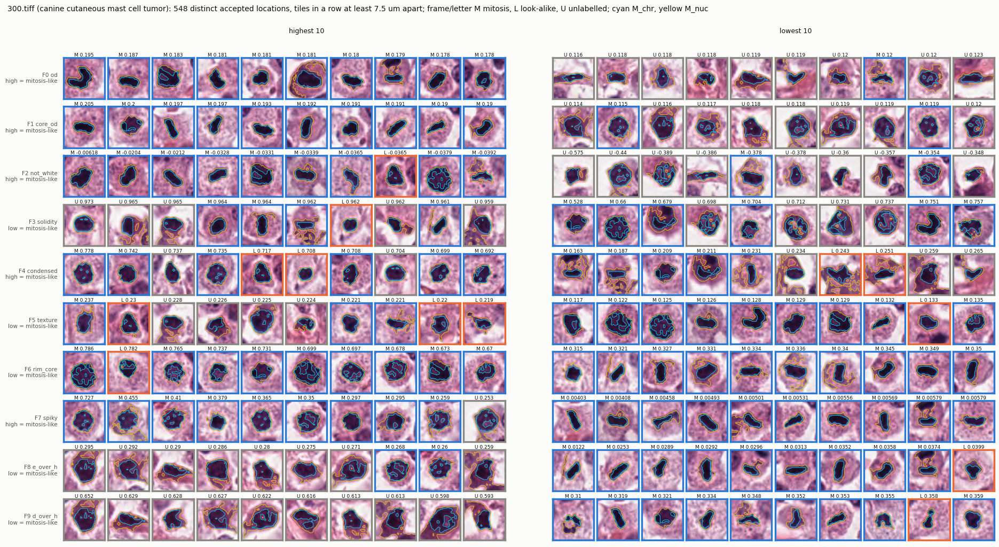

-> candrefine_select_montage_300.png


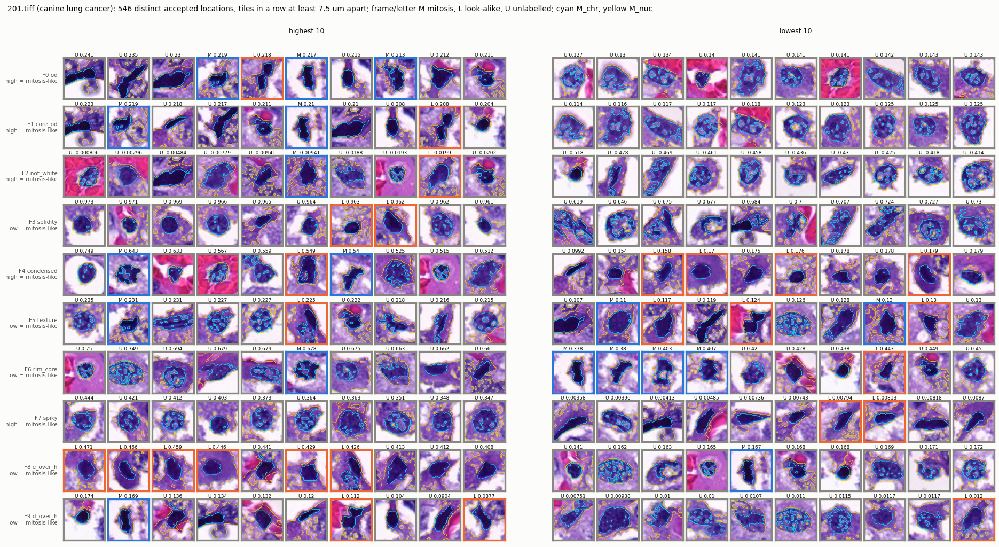

-> candrefine_select_montage_201.png


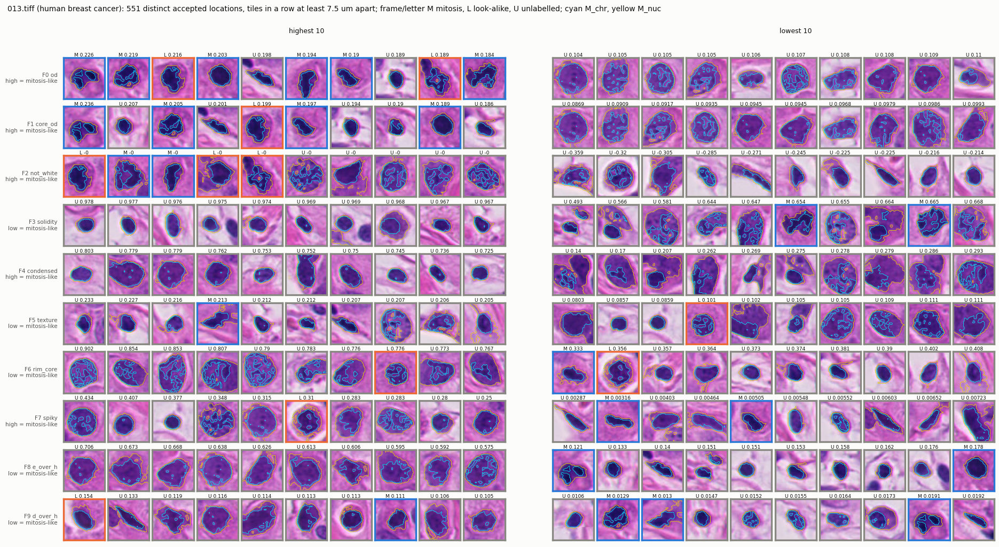

-> candrefine_select_montage_013.png


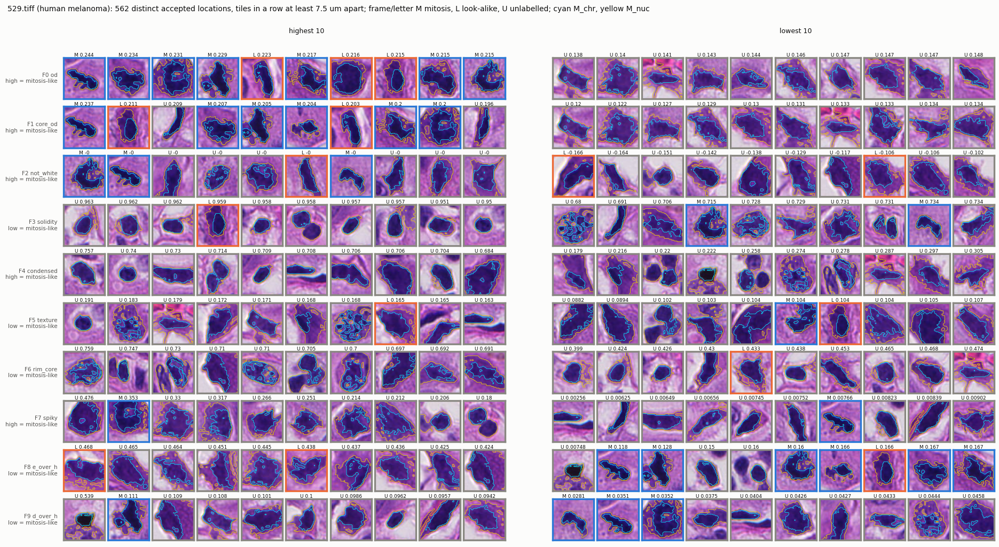

-> candrefine_select_montage_529.png


In [13]:
SURFACE, INK, SECONDARY = '#fcfcfb', '#0b0b0b', '#52514e'
LABEL_STYLE = {'mitosis': ('#2a78d6', 'M'), 'look-alike': ('#eb6834', 'L'), 'unlabelled': ('#898781', 'U')}
ARROW = {1: 'high = mitosis-like', -1: 'low = mitosis-like'}
assert POOL.groupby(['file_name', 'cx', 'cy'])['od'].nunique().max() == 1, 'od differs between clicks at one location'
LOC = FEAT.merge(POOL.drop_duplicates(['file_name', 'cx', 'cy'])[['file_name', 'cx', 'cy', 'od']], on=['file_name', 'cx', 'cy'], how='left', validate='one_to_one')
def spaced(loc, order, radius):
    """
        The first MONTAGE_N locations of a sorted order, skipping any within radius of one already taken, so a nucleus found by several clicks shows once.

        loc (pd.DataFrame): the ROI's distinct accepted locations, with cx, cy.
        order (pd.Index): loc's index, sorted by the feature.
        radius (float): the skip distance in pixels, ev.radius_px(mpp).

        Returns list: up to MONTAGE_N index labels of loc.
    """
    taken = []
    for idx in order:
        x, y = loc.at[idx, 'cx'], loc.at[idx, 'cy']
        if all(np.hypot(x - loc.at[j, 'cx'], y - loc.at[j, 'cy']) > radius for j in taken):
            taken.append(idx)
        if len(taken) == MONTAGE_N:
            break
    return taken


MPP_OF = CLICKS.drop_duplicates('file_name').set_index('file_name')['mpp']
first_label = LAB.sort_values(['file_name', 'seed_index', 'tm_rank'], kind='mergesort').drop_duplicates(['file_name', 'cx', 'cy']).set_index(['file_name', 'cx', 'cy'])['label_short']
for f in [m for m in MONTAGE_ROIS if m in ROI_ORDER]:
    loc = LOC[(LOC['file_name'] == f) & LOC['accepted']].reset_index(drop=True)
    radius = ev.radius_px(MPP_OF[f])
    fig, axes = plt.subplots(len(FEATURE_TERMS), 2 * MONTAGE_N + 1, figsize=(0.82 * (2 * MONTAGE_N + 1) + 1.6, 0.98 * len(FEATURE_TERMS) + 0.6), facecolor=SURFACE)
    for j, t in enumerate(FEATURE_TERMS):
        col = COLUMN[t]
        v = loc[col].dropna()
        hi = spaced(loc, v.sort_values(ascending=False, kind='mergesort').index, radius)
        lo = spaced(loc, v.sort_values(ascending=True, kind='mergesort').index, radius)
        slots = list(hi) + [None] * (MONTAGE_N - len(hi)) + [None] + list(lo) + [None] * (MONTAGE_N - len(lo))
        for k, idx in enumerate(slots):
            ax = axes[j, k]
            ax.set_xticks([])
            ax.set_yticks([])
            if idx is None:
                ax.set_frame_on(False)   # frame off, not axis off, so column 0 keeps its row label
                continue
            q = loc.loc[idx]
            m = MONTAGE[(f, q['cx'], q['cy'])]
            colour, letter = LABEL_STYLE[first_label[(f, q['cx'], q['cy'])]]
            ax.imshow(m['crop'])
            ax.contour(m['m_nuc'].astype(float), levels=[0.5], colors='#f2d200', linewidths=0.6)
            ax.contour(m['m_chr'].astype(float), levels=[0.5], colors='#00e5ff', linewidths=0.6)
            for sp in ax.spines.values():
                sp.set_edgecolor(colour)
                sp.set_linewidth(2.4)
            ax.set_title(f'{letter} {q[col]:.3g}', fontsize=6.5, color=INK, pad=1.5)
        d = DIR_ALL[t]
        axes[j, 0].set_ylabel(f'{t} {col}\n{ARROW[d]}', fontsize=7.5, color=SECONDARY, rotation=0, ha='right', va='center', labelpad=8)
    axes[0, MONTAGE_N // 2].annotate(f'highest {MONTAGE_N}', (0.5, 1.6), xycoords='axes fraction', ha='center', fontsize=9, color=INK)
    axes[0, MONTAGE_N + 1 + MONTAGE_N // 2].annotate(f'lowest {MONTAGE_N}', (0.5, 1.6), xycoords='axes fraction', ha='center', fontsize=9, color=INK)
    fig.suptitle(f"{f} ({DOMAIN_OF[f]}): {len(loc)} distinct accepted locations, tiles in a row at least 7.5 um apart; frame/letter M mitosis, L look-alike, U unlabelled; cyan M_chr, yellow M_nuc", fontsize=10, color=INK, x=0.01, ha='left')
    fig.tight_layout(rect=(0, 0, 1, 0.97), h_pad=0.6, w_pad=0.15)
    fig.savefig(MONTAGE_PATHS[f], dpi=110, facecolor=SURFACE)
    plt.show()
    plt.close(fig)
    print(f'-> {MONTAGE_PATHS[f]}')

## Outputs

In [14]:
CLICK_OUT = TRIP.merge(PER_RUN[PER_RUN['arm'] == 'od'][['file_name', 'seed_index', 'pool_source', 'n_gt_mitotic', 'n_pool', 'n_accepted']], on=['file_name', 'seed_index'], validate='one_to_one')
POOL_OUT = POOL.drop(columns=['bucket_short'])
for name, frame in (('clicks', CLICK_OUT), ('pool', POOL_OUT), ('auc', AUC), ('combos', COMBO_TABLE), ('per_run', PER_RUN), ('per_roi', PER_ROI), ('delta_stats', DELTAS), ('refusals', REFUSALS.reset_index())):
    frame.to_csv(OUT[name], index=False)
    print(f'-> {OUT[name]} ({len(frame)} rows)')
with open(SPEC_PATH, 'wb') as fh:
    fh.write(SPEC_BYTES)
with open(SPEC_PATH, 'rb') as fh:
    assert hashlib.sha1(fh.read()).hexdigest() == SPEC_SHA1
print(f'-> {SPEC_PATH} (SHA-1 {SPEC_SHA1})')
print(f'\nnotebook total {(time.time() - NB_T0) / 60:.1f} min')

-> ../../results/candrefine_rerank_mo_pad61_select_clicks.csv (294 rows)


-> ../../results/candrefine_rerank_mo_pad61_select_pool.csv (29107 rows)
-> ../../results/candrefine_rerank_mo_pad61_select_auc.csv (550 rows)
-> ../../results/candrefine_rerank_mo_pad61_select_combos.csv (40 rows)
-> ../../results/candrefine_rerank_mo_pad61_select_per_run.csv (3234 rows)
-> ../../results/candrefine_rerank_mo_pad61_select_per_roi.csv (539 rows)
-> ../../results/candrefine_rerank_mo_pad61_select_delta_stats.csv (54 rows)
-> ../../results/candrefine_rerank_mo_pad61_select_refusals.csv (5 rows)
-> candrefine_rerank_spec.json (SHA-1 31392ada769cd37563454fb1f529ef660fc81154)

notebook total 9.1 min


## Checkpoint (plan Section 9, step 2)

Stop here and report to the user: the montages, the per-feature AUCs, the fold picks and the spec. The verdict
notebook runs only after that. A change to any feature definition means re-running this notebook, which gives a new
spec and a new SHA-1.